# Does Architecture Matter for Fairness? ViT vs CNN on Dollar Street

**Research question.** Do Vision Transformers (ViTs) and Convolutional Neural Networks (CNNs) differ in how well they recognise everyday household objects across homes of different income levels and world regions?

**Design overview**
- **Data:** a 14-class subset of the Dollar Street dataset (Gaviria Rojas et al., 2022). Each photo carries the household's monthly income, region and country.
- **Models:** all pretrained on ImageNet-21k and fine-tuned with an identical recipe, so the comparison is controlled:
  - CNNs: ResNet-50 (BiT-M), ConvNeXt-Tiny
  - ViTs: ViT-S/16 (parameter-matched to the CNNs), ViT-B/16
- **Rigour:**
  - 3 seeds per model
  - household-grouped splits (no home in both train and test)
  - cluster-bootstrap confidence intervals
  - logistic-regression confound analysis (image quality, class, region)
  - calibration, embedding probes and Grad-CAM
- **Additional experiments:**
  - (a) a learning-rate sensitivity check
  - (b) a frozen-embedding linear-probe baseline
  - (c) a bias-mitigation experiment with income-balanced sampling

**Runtime:** about 2.5–3.5 h on a Colab T4. Everything is cached to Google Drive, so after a disconnect you can re-run all cells and finished steps are skipped.

> Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all.

## 1. Setup
Install the two libraries that Colab does not ship with:
- `timm`: the PyTorch Image Models library, a collection of pretrained ViTs and CNNs
- `grad-cam`: heat-map explanations of model decisions

In [4]:
# -q = quiet install (less output)
!pip -q install timm grad-cam

In [3]:
# ---------- Standard-library imports ----------
import os
import re
import io
import json
import time
import math
import random
import shutil
import glob
import warnings

# ---------- Data-science imports ----------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from IPython.display import display

# ---------- Deep-learning imports ----------
import torch
import torch.nn as nn
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import timm
from tqdm.auto import tqdm

# ---------- Metrics ----------
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')   # hide deprecation warnings so the output stays readable
Image.MAX_IMAGE_PIXELS = None       # some Dollar Street photos are very large; allow them to load

# ---------- Clean output (cosmetic only: results are unchanged) ----------
import sys, logging
sys.unraisablehook = lambda *args: None                      # hide harmless "Exception ignored ... can only test a child process" DataLoader cleanup messages (PyTorch + Python 3.13)
logging.getLogger('huggingface_hub').setLevel(logging.ERROR)  # hide the "unauthenticated requests to the HF Hub" warning
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'             # hide Hugging Face download progress bars (our own tqdm bars still show)

# ---------- Where to store files ----------
try:                                                    # if we are running on Google Colab...
    from google.colab import drive                      # ...import the Drive helper
    drive.mount('/content/drive')                       # ...connect Google Drive (asks for permission)
    PROJ = '/content/drive/MyDrive/dollarstreet_vit_vs_cnn'  # results live on Drive (survive disconnects)
    DATA = '/content/data'                              # images live on fast local Colab disk
except ImportError:                                     # if running locally instead of Colab...
    PROJ, DATA = './outputs', './data'                  # ...use local folders

IMG_DIR = f'{DATA}/images'        # folder for the resized images
FIG = f'{PROJ}/figures'           # folder for saved figures (for the report)
TAB = f'{PROJ}/tables'            # folder for saved tables (CSV, for the report)
RUNS = f'{PROJ}/runs'             # predictions of the main experiments
EXTRA = f'{PROJ}/runs_extra'      # predictions of the additional experiments
CKPT = f'{PROJ}/checkpoints'      # saved model weights (seed 0 only, for Grad-CAM)
for d in [PROJ, FIG, TAB, RUNS, EXTRA, CKPT, IMG_DIR]:  # loop over every folder...
    os.makedirs(d, exist_ok=True)                       # ...and create it if it does not exist

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'      # use the GPU if there is one
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')  # confirm GPU type
print('torch', torch.__version__, '| timm', timm.__version__)                       # record library versions

sns.set_theme(style='whitegrid', context='notebook')                           # consistent plot style
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})  # sharp saved figures

def savefig(name):                       # helper: save the current figure to Drive and show it
    plt.savefig(f'{FIG}/{name}.png')     # save as PNG (200 dpi, good for the report)
    plt.show()                           # display it in the notebook

def set_seed(s):                         # helper: make random results reproducible
    random.seed(s)                       # Python random
    np.random.seed(s)                    # NumPy random
    torch.manual_seed(s)                 # PyTorch CPU random
    torch.cuda.manual_seed_all(s)        # PyTorch GPU random

Mounted at /content/drive
Device: cuda Tesla T4
torch 2.11.0+cu130 | timm 1.0.30


## 2. Configuration

**Class selection rationale.** We keep everyday objects that every household has in *some* form but that vary sharply in appearance with income (e.g. a stove can be a gas range or an open fire). Each chosen class also has more than 250 images in the dataset. We avoid overlapping topics (e.g. `toilet` vs `bathroom_toilet`).

**Model selection rationale.**
- All four backbones are **ImageNet-21k pretrained**, which removes pretraining data as a confound.
- **ViT-S/16 (22M), ConvNeXt-T (28M) and ResNet-50 (25M)** are parameter-matched.
- **ViT-B/16 (86M)** tests whether scale changes the picture.
- **ConvNeXt** is a "modernised" CNN that borrows ViT design choices (Liu et al., 2022), which makes it a strong, fair CNN baseline.

In [5]:
# The 14 Dollar Street topics we use as classes (names exactly as in the dataset)
CLASSES = ['stove_hob', 'toothbrush', 'toilet', 'refrigerator', 'wardrobe', 'kitchen_sink', 'cooking_pots',
           'plates', 'front_door', 'tv', 'phone', 'couch', 'bed', 'shower']

# Human-readable names for plots
PRETTY = {'stove_hob': 'stove', 'toothbrush': 'toothbrush', 'toilet': 'toilet', 'refrigerator': 'refrigerator',
          'wardrobe': 'wardrobe', 'kitchen_sink': 'kitchen sink', 'cooking_pots': 'cooking pot', 'plates': 'plate',
          'front_door': 'front door', 'tv': 'television', 'phone': 'phone', 'couch': 'couch', 'bed': 'bed',
          'shower': 'shower'}
NAMES = [PRETTY[c] for c in CLASSES]   # readable names in the same order as CLASSES (index = label number)

MAX_PER_CLASS = 450    # cap the very large classes (toilet, bed, front_door) so no class dominates
IMG_SHORT_SIDE = 256   # store images with their short side at 256 px (originals are up to ~8000 px)
SEEDS = [0, 1, 2]      # each model is trained 3 times with different random seeds

# The four models to compare. 'timm' = the exact pretrained checkpoint name in the timm library.
# 'cam_layer' = the layer whose activations Grad-CAM visualises (used in Section 13).
MODELS = {
    'ResNet50-BiT': dict(timm='resnetv2_50x1_bit.goog_in21k_ft_in1k',        family='CNN', cam_layer='norm'),
    'ConvNeXt-T':   dict(timm='convnext_tiny.fb_in22k_ft_in1k',              family='CNN', cam_layer='stages.3'),
    'ViT-S/16':     dict(timm='vit_small_patch16_224.augreg_in21k_ft_in1k',  family='ViT', cam_layer='blocks.11.norm1'),
    'ViT-B/16':     dict(timm='vit_base_patch16_224.augreg2_in21k_ft_in1k',  family='ViT', cam_layer='blocks.11.norm1'),
}

# Training recipe, identical for every model (fair comparison)
CFG = dict(
    img_size=224,          # input resolution seen by every model
    epochs=12,             # maximum number of passes over the training set
    batch_size=32,         # images per training step (fits in T4 memory with mixed precision)
    lr_backbone=5e-5,      # small learning rate for the pretrained layers (don't destroy what they know)
    lr_head=5e-4,          # 10x larger learning rate for the new, randomly-initialised classifier head
    weight_decay=0.05,     # L2-style regularisation used by AdamW
    warmup_epochs=1,       # linearly increase the learning rate during the first epoch (stabilises training)
    label_smoothing=0.1,   # soften the one-hot targets (reduces over-confidence)
    patience=4,            # stop early if validation macro-F1 has not improved for 4 epochs
    num_workers=2,         # parallel image-loading processes (Colab has 2 CPU cores)
)

MODEL_ORDER = list(MODELS)                 # order in which models appear in tables and plots
PALETTE = dict(zip(MODEL_ORDER, ['#9ecae1', '#2171b5', '#fdae6b', '#d94801']))  # CNN = blues, ViT = oranges
slug = lambda n: re.sub(r'[^A-Za-z0-9]+', '_', n)  # turn a model name like 'ViT-B/16' into a safe file name 'ViT_B_16'

## 3. Data acquisition and pre-processing

The official release on Kaggle is 101 GB. We instead use the Hugging Face mirror `iamshnoo/dollarstreet`, which stores **one parquet file per topic**, so we only download the 14 classes we need (about 19 GB).

For each image we:
1. decode it and apply the EXIF orientation;
2. convert it to RGB;
3. resize the short side to 256 px and save it as a JPEG;
4. record image-quality statistics (brightness, contrast, sharpness, colourfulness) for the later confound analysis.

The processed images (~150 MB) are tarred to Drive, so this step runs only once.

In [6]:
from huggingface_hub import HfApi, hf_hub_download   # tools to list and download files from Hugging Face
import pyarrow.parquet as pq                          # reads .parquet files (a compressed table format)

REPO = 'iamshnoo/dollarstreet'           # the Hugging Face dataset repository
META_RAW = f'{PROJ}/metadata_raw.csv'    # where we save the metadata table of all processed images
TAR = f'{PROJ}/images.tar'               # where we save a backup archive of the resized images

def quality_stats(img):
    """Simple image-quality measurements used later to test whether quality (not income) explains errors."""
    g = np.asarray(img.convert('L'), dtype=np.float32)                       # greyscale pixel values 0-255
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]  # Laplacian filter = edge strength
    a = np.asarray(img, dtype=np.float32)                                    # colour pixel values
    rg = a[..., 0] - a[..., 1]                                               # red-green opponent channel
    yb = 0.5 * (a[..., 0] + a[..., 1]) - a[..., 2]                           # yellow-blue opponent channel
    colorful = np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean())  # colourfulness (Hasler & Suesstrunk, 2003)
    return dict(brightness=g.mean(),      # average brightness (dark photos -> low value)
                contrast=g.std(),         # spread of brightness values
                sharpness=lap.var(),      # variance of edges (blurry photos -> low value)
                colorfulness=colorful)    # how vivid the colours are

def process_bytes(b):
    """Decode raw image bytes, fix rotation, convert to RGB and shrink so the short side is 256 px."""
    img = Image.open(io.BytesIO(b))                              # open the image from bytes in memory
    img.draft('RGB', (IMG_SHORT_SIDE * 2, IMG_SHORT_SIDE * 2))   # ask the JPEG decoder for a smaller version (much faster)
    img = ImageOps.exif_transpose(img).convert('RGB')            # rotate according to camera EXIF tag; force 3 colour channels
    w, h = img.size                                              # current width and height
    s = IMG_SHORT_SIDE / min(w, h)                               # scale factor so the shorter side becomes 256
    new_size = (max(1, round(w * s)), max(1, round(h * s)))      # new width and height (keeps aspect ratio)
    return img.resize(new_size, Image.BICUBIC), (w, h)           # return resized image and original size

if os.path.exists(META_RAW) and os.path.exists(TAR):     # if we already processed the data in an earlier session...
    print('Restoring cached images from Drive...')
    shutil.unpack_archive(TAR, DATA)                     # ...just unpack the backup archive (fast)
    raw = pd.read_csv(META_RAW)                          # ...and reload the metadata table
else:                                                    # otherwise download and process everything (runs once)
    files = HfApi().list_repo_files(REPO, repo_type='dataset')   # list every file in the HF repository
    rows = []                                                    # one dictionary of metadata per image
    for cls in CLASSES:                                          # for each class we want...
        pattern = rf'data/{re.escape(cls)}-\d+-of-\d+.*\.parquet'          # file-name pattern for that topic
        cls_files = [f for f in files if re.fullmatch(pattern, f)]        # find its parquet file(s)
        assert cls_files, f'no parquet found for {cls}'                    # stop with a clear error if missing
        for f in cls_files:                                                # usually just one file per topic
            local = hf_hub_download(REPO, f, repo_type='dataset', local_dir=f'{DATA}/parquet')  # download it
            pf = pq.ParquetFile(local)                                     # open the parquet file
            n_batches = math.ceil(pf.metadata.num_rows / 16)               # number of 16-row chunks (for the progress bar)
            for batch in tqdm(pf.iter_batches(batch_size=16), desc=cls, total=n_batches):  # read 16 rows at a time (saves RAM)
                for r in batch.to_pylist():                                # each r is one image + its metadata
                    try:
                        img, (w, h) = process_bytes(r['image']['bytes'])   # decode and resize the image
                    except Exception as e:                                 # a few files may be corrupt...
                        print('skip', r.get('id'), e)                      # ...report them...
                        continue                                           # ...and move on
                    fn = f"{r['id']}.jpg"                                  # file name = Dollar Street image id
                    img.save(f'{IMG_DIR}/{fn}', quality=92)                # save the resized JPEG
                    rows.append(dict(id=r['id'], cls=cls, file=fn,         # remember metadata for this image
                                     income=r['income'],                   # household monthly income (USD, PPP)
                                     region_id=r['region_id'],             # continent code: af / am / as / eu
                                     country=r['country_name'],            # country name
                                     country_id=r['country_id'],           # country code
                                     place=r['place'],                     # household identifier
                                     topics=r['topics'],                   # all topics this image is tagged with
                                     orig_w=w, orig_h=h,                   # original resolution
                                     **quality_stats(img)))                # brightness, sharpness, etc.
            os.remove(local)                                               # delete the big parquet file to free disk space
    raw = pd.DataFrame(rows)                                     # turn the list of dicts into a table
    raw.to_csv(META_RAW, index=False)                            # save the metadata to Drive
    shutil.make_archive(TAR[:-4], 'tar', DATA, 'images')         # back up the resized images to Drive
print(raw.shape)    # (number of images, number of columns)
raw.head()          # show the first rows

Restoring cached images from Drive...
(6204, 15)


,id,cls,file,income,region_id,country,country_id,place,topics,orig_w,orig_h,brightness,contrast,sharpness,colorfulness
0,5d4bf320cf0b3a0f3f35988e,stove_hob,5d4bf320cf0b3a0f3f35988e.jpg,26.994581,af,Burundi,bi,butoyi,Stove/hob,1404,936,60.018017,50.949560,742.0254,47.206882
1,5d4bf330cf0b3a0f3f359a2e,stove_hob,5d4bf330cf0b3a0f3f359a2e.jpg,28.500000,af,Burundi,bi,kabura,Stove/hob,1404,936,72.091286,53.458990,596.0169,48.733948
2,5d4bf472cf0b3a0f3f35ba86,stove_hob,5d4bf472cf0b3a0f3f35ba86.jpg,28.861213,af,Burkina Faso,bf,kabore,Stove/hob,1350,900,96.464170,47.056206,2962.6128,23.271523
3,5d4beaa8cf0b3a0f3f34ad7c,stove_hob,5d4beaa8cf0b3a0f3f34ad7c.jpg,29.031387,as,India,in,chowdhury,Stove/hob,1152,768,96.294590,43.414480,1052.4165,19.009840
4,5d4befdbcf0b3a0f3f353f6c,stove_hob,5d4befdbcf0b3a0f3f353f6c.jpg,30.184425,af,Malawi,mw,njoka,Stove/hob,1152,768,91.853850,28.964674,1280.0441,21.329868


**Sanity check of the metadata.** `place` should identify a household; we use it as the grouping key for splits and bootstrap. Check the output below.

In [7]:
print('unique images:', raw.id.nunique(),            # how many distinct photos
      '| unique places:', raw.place.nunique(),       # how many distinct households
      '| countries:', raw.country.nunique())         # how many countries
print(raw[['place', 'country', 'income', 'region_id']].drop_duplicates().head(8))  # peek at household-level info
print('images per place (>1 means several objects photographed in the same home):')
print(raw.groupby('place').id.nunique().describe())  # summary statistics of photos per household

unique images: 6175 | unique places: 396 | countries: 63
       place       country     income region_id
0     butoyi       Burundi  26.994581        af
1     kabura       Burundi  28.500000        af
2     kabore  Burkina Faso  28.861213        af
3  chowdhury         India  29.031387        as
4      njoka        Malawi  30.184425        af
5     tarimo      Tanzania  32.000000        af
6       idle       Somalia  34.500000        af
7     majuru      Zimbabwe  34.420780        af
images per place (>1 means several objects photographed in the same home):
count    396.000000
mean      15.593434
std        3.030454
min        1.000000
25%       14.000000
50%       16.000000
75%       18.000000
max       22.000000
Name: id, dtype: float64


### 3.1 Curation
- **Remove ambiguous images.** An image tagged with more than one of our classes (e.g. a kitchen photo showing both stove and sink) is dropped, because it has no single correct label.
- **Cap large classes** at 450 images.
- **Income bands** are quartiles computed over *households*, not images, so each band contains about 25% of homes.

In [8]:
df = raw.copy()                                                    # work on a copy of the raw table
df['income'] = pd.to_numeric(df['income'], errors='coerce')        # income is stored as text -> convert to numbers
df = df.dropna(subset=['income'])                                  # drop the (rare) images with no income value

n_classes_per_img = df.groupby('id').cls.nunique()                 # how many of OUR classes each image is tagged with
multi = n_classes_per_img[n_classes_per_img > 1].index             # ids of images with more than one of our classes
print(f'dropping {len(multi)} images tagged with >1 target class')
df = df[~df.id.isin(multi)].drop_duplicates('id')                  # remove ambiguous images and any duplicates

fallback_hh = df.country_id.astype(str) + '_' + df.income.astype(str)  # backup household key (country + income) if 'place' is missing
df['household'] = df['place'].fillna(fallback_hh).astype(str)          # household identifier used for grouping

df = (df.groupby('cls', group_keys=False)                                       # for each class...
        .apply(lambda g: g.sample(min(len(g), MAX_PER_CLASS), random_state=0))  # ...randomly keep at most 450 images
        .reset_index(drop=True))                                                # clean 0..N-1 row numbering

region_names = {'af': 'Africa', 'am': 'Americas', 'as': 'Asia', 'eu': 'Europe'}  # region code -> readable name
df['region'] = df.region_id.map(region_names).fillna(df.region_id)                # add readable region column

hh_income = df.groupby('household').income.first()          # one income value per household
q = hh_income.quantile([.25, .5, .75]).values               # 25th, 50th, 75th percentile = band boundaries
BANDS = ['Q1', 'Q2', 'Q3', 'Q4']                            # Q1 = poorest quarter of homes, Q4 = richest
BAND_LABELS = {'Q1': f'Q1 <${q[0]:.0f}',                    # readable labels with the dollar thresholds
               'Q2': f'Q2 ${q[0]:.0f}-{q[1]:.0f}',
               'Q3': f'Q3 ${q[1]:.0f}-{q[2]:.0f}',
               'Q4': f'Q4 >${q[2]:.0f}'}
df['income_band'] = pd.cut(df.income, [-np.inf, *q, np.inf], labels=BANDS).astype(str)  # assign each image a band
df['log_income'] = np.log10(df.income)                                                   # log scale (income is very skewed)
df['label'] = df.cls.map({c: i for i, c in enumerate(CLASSES)})                          # class name -> integer label 0..13
df['log_sharpness'] = np.log10(df.sharpness + 1)                                         # sharpness is skewed too -> log
print('Income quartile thresholds (USD/month):', np.round(q, 0))
print(df.shape)

dropping 29 images tagged with >1 target class
Income quartile thresholds (USD/month): [ 151.  464. 1579.]
(5002, 21)


### 3.2 Exploratory analysis

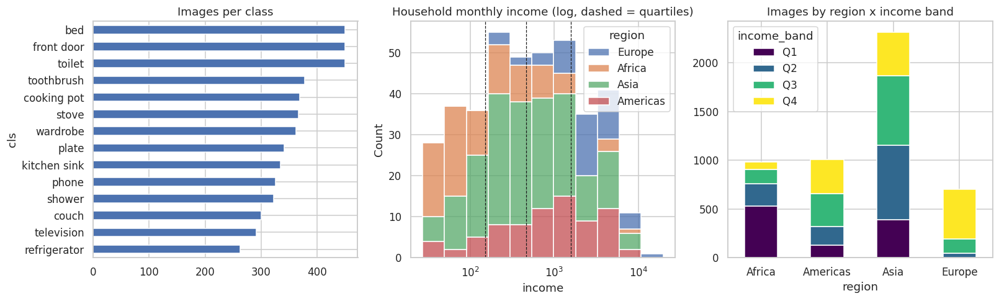

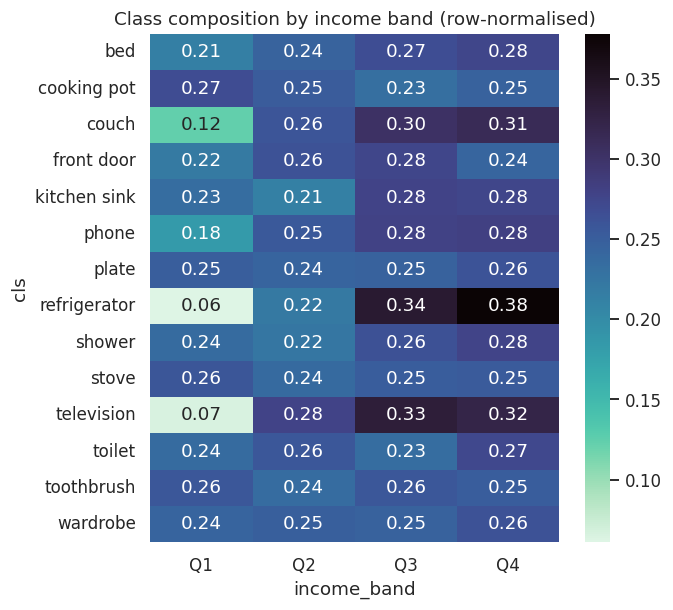

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))                          # three plots side by side

df.cls.map(PRETTY).value_counts().plot.barh(ax=ax[0], color='#4c72b0')   # (a) number of images per class
ax[0].set_title('Images per class')
ax[0].invert_yaxis()                                                     # largest class at the top

households = df.drop_duplicates('household')                             # one row per household
sns.histplot(households, x='income', hue='region', log_scale=True, multiple='stack', ax=ax[1])  # (b) income distribution
for t in q:                                                              # draw the quartile boundaries...
    ax[1].axvline(t, ls='--', c='k', lw=.8)                              # ...as dashed vertical lines
ax[1].set_title('Household monthly income (log, dashed = quartiles)')

pd.crosstab(df.region, df.income_band).plot.bar(stacked=True, ax=ax[2], colormap='viridis', rot=0)  # (c) region x band counts
ax[2].set_title('Images by region x income band')
savefig('eda_overview')

ct = pd.crosstab(df.cls.map(PRETTY), df.income_band, normalize='index')   # share of each class's images in each band
plt.figure(figsize=(6, 6))
sns.heatmap(ct, annot=True, fmt='.2f', cmap='mako_r')                     # heat-map with the numbers written in
plt.title('Class composition by income band (row-normalised)')
savefig('eda_class_by_income')

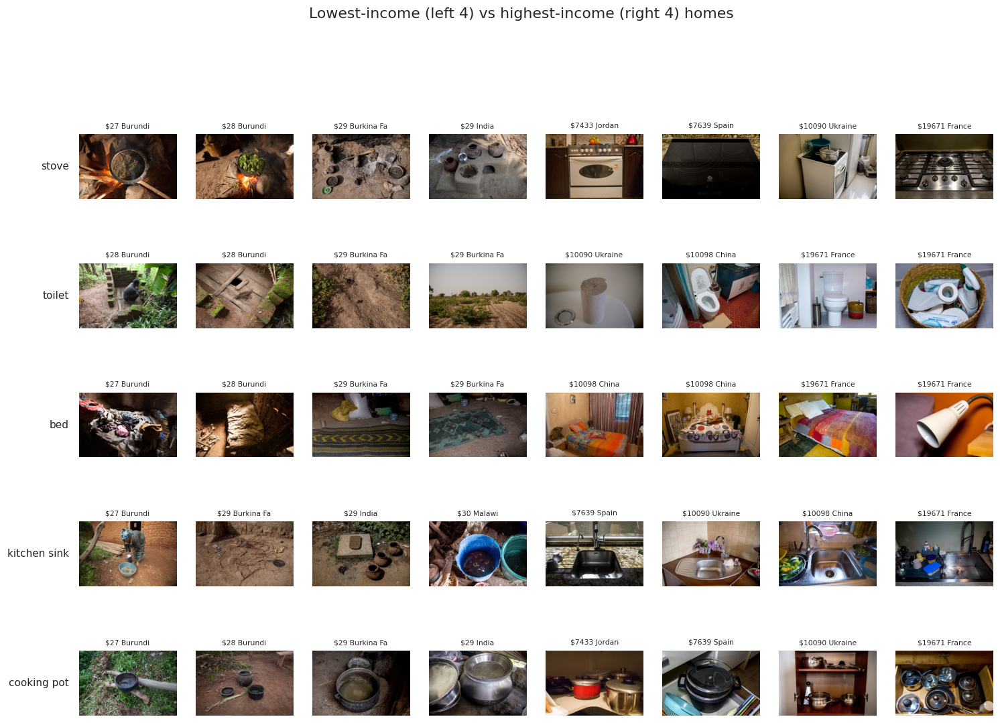

In [10]:
def show_low_high(classes, n=4, fname='eda_low_vs_high'):
    """Show the n lowest-income and n highest-income photos for each class, side by side."""
    fig, axes = plt.subplots(len(classes), 2 * n, figsize=(4 * n, 2.2 * len(classes)))  # grid: one row per class
    for i, c in enumerate(classes):                                        # for each class (row)...
        sub = df[df.cls == c].sort_values('income')                        # ...its images sorted by income
        picks = pd.concat([sub.head(n), sub.tail(n)])                      # ...n poorest + n richest
        for j, (_, r) in enumerate(picks.iterrows()):                      # for each chosen image (column)...
            a = axes[i, j]
            a.imshow(Image.open(f'{IMG_DIR}/{r.file}'))                    # ...draw the photo
            a.axis('off')                                                  # ...hide the axes
            a.set_title(f'${r.income:.0f} {r.country[:10]}', fontsize=7)   # ...caption with income and country
        axes[i, 0].text(-0.1, .5, PRETTY[c], transform=axes[i, 0].transAxes, ha='right', va='center', fontsize=10)  # row label
    fig.suptitle(f'Lowest-income (left {n}) vs highest-income (right {n}) homes', y=1.01)
    savefig(fname)

show_low_high(['stove_hob', 'toilet', 'bed', 'kitchen_sink', 'cooking_pots'])   # classes where appearance varies most

**Image-quality confounds.** If photos from poorer homes are systematically darker or blurrier, an accuracy gap may reflect image quality rather than appearance. We measure this here and control for it in Section 9.

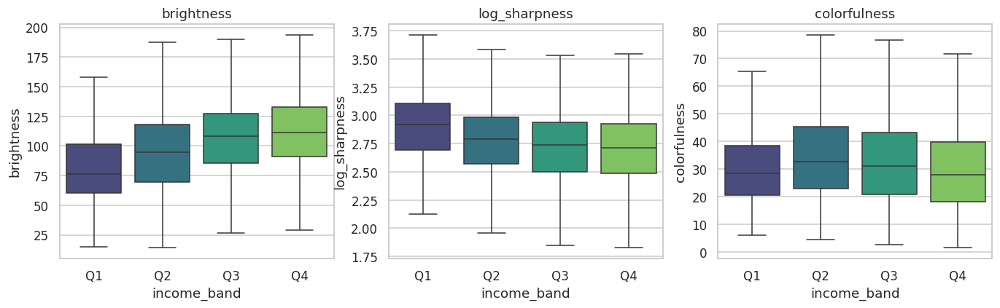

,brightness,log_sharpness,colorfulness,orig_w
income_band,,,,
Q1,76.28,2.92,28.40,1152.0
Q2,94.61,2.79,32.81,1000.0
Q3,107.98,2.74,31.01,1000.0
Q4,111.29,2.71,27.97,1008.0


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))                       # three box-plots side by side
for a, col in zip(ax, ['brightness', 'log_sharpness', 'colorfulness']):  # one quality measure per plot
    sns.boxplot(df, x='income_band', y=col, order=BANDS, ax=a, palette='viridis', showfliers=False)  # distribution per band
    a.set_title(col)
savefig('eda_quality_by_income')
df.groupby('income_band')[['brightness', 'log_sharpness', 'colorfulness', 'orig_w']].median().round(2)  # median per band

### 3.3 Household-grouped, class-stratified splits (70 / 15 / 15)
Images from the same home share background, lighting and camera. A random split would leak this information, so we use `StratifiedGroupKFold` with household as the group.

In [12]:
from sklearn.model_selection import StratifiedGroupKFold   # splits data keeping groups intact and classes balanced

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)   # 1/7 ~ 14-15% of data for testing
trval_idx, test_idx = next(sgkf.split(df, df.label, df.household))       # take the first fold as the test set
trval = df.iloc[trval_idx]                                               # remaining ~85% = train + validation

sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)  # split the remainder again (1/6 -> validation)
tr_i, va_i = next(sgkf2.split(trval, trval.label, trval.household))      # first fold = validation set

train_df = trval.iloc[tr_i].reset_index(drop=True)    # ~70% training images
val_df = trval.iloc[va_i].reset_index(drop=True)      # ~15% validation images (for early stopping / tuning)
test_df = df.iloc[test_idx].reset_index(drop=True)    # ~15% test images (touched only for final evaluation)

assert not (set(train_df.household) & set(test_df.household))   # check: no household in both train and test
assert not (set(val_df.household) & set(test_df.household))     # check: no household in both val and test
for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]:   # print size and income mix of each split
    print(f'{n:5s} {len(d):5d} imgs, {d.household.nunique():4d} homes |', d.income_band.value_counts().sort_index().to_dict())
df.to_csv(f'{PROJ}/metadata_clean.csv', index=False)      # save the cleaned metadata
test_df.to_csv(f'{PROJ}/test_split.csv', index=False)     # save the exact test split (reproducibility)
print('countries per split:', {n: d.country.nunique() for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]})  # for Table 1 of the report

train  3627 imgs,  285 homes | {'Q1': 721, 'Q2': 904, 'Q3': 993, 'Q4': 1009}
val     674 imgs,   54 homes | {'Q1': 158, 'Q2': 155, 'Q3': 229, 'Q4': 132}
test    701 imgs,   57 homes | {'Q1': 172, 'Q2': 170, 'Q3': 121, 'Q4': 238}
countries per split: {'train': 59, 'val': 30, 'test': 31}


## 4. Models, pre-processing pipeline and training recipe

**Model-specific pre-processing.** Normalisation mean and std are read from each checkpoint's pretrained config. For example, the AugReg ViTs and BiT expect (0.5, 0.5, 0.5), while ConvNeXt expects ImageNet statistics. All models use 224×224 input, so they see the same pixels.

**Augmentation (train only):**
- `RandomResizedCrop(224, scale=(0.5, 1))` and horizontal flip
- no colour jitter, because brightness is a variable we analyse

**Evaluation:** resize to 256, then centre crop to 224.

**Identical fine-tuning recipe for all models:**
- full fine-tuning with AdamW (backbone learning rate 5e-5, new head 5e-4, weight decay 0.05)
- 1 epoch of linear warmup, then cosine decay
- label smoothing 0.1, gradient clipping at 1.0, mixed precision (AMP)
- 12 epochs maximum, with early stopping (patience 4) on validation macro-F1

In [13]:
class DSData(Dataset):
    """PyTorch Dataset: returns (pre-processed image tensor, integer label) for row i of a table."""
    def __init__(self, frame, tf):
        self.files = frame.file.tolist()     # list of image file names
        self.labels = frame.label.tolist()   # list of integer labels
        self.tf = tf                         # the transform (pre-processing) to apply
    def __len__(self):
        return len(self.files)               # number of images
    def __getitem__(self, i):
        img = Image.open(f'{IMG_DIR}/{self.files[i]}').convert('RGB')   # load image i from disk
        return self.tf(img), self.labels[i]                              # pre-process it and return with its label

def make_tfms(model):
    """Build train and test pre-processing pipelines that match the model's expected normalisation."""
    cfg = timm.data.resolve_model_data_config(model)    # read the mean/std this checkpoint was trained with
    norm = T.Normalize(cfg['mean'], cfg['std'])         # normalise pixel values the same way
    s = CFG['img_size']                                 # 224
    train = T.Compose([
        T.RandomResizedCrop(s, scale=(0.5, 1.0)),       # random crop covering 50-100% of the image, resized to 224
        T.RandomHorizontalFlip(),                       # mirror the image half the time
        T.ToTensor(),                                   # PIL image -> tensor with values 0..1
        norm,                                           # model-specific normalisation
    ])
    test = T.Compose([
        T.Resize(int(s * 256 / 224)),                   # resize short side to 256
        T.CenterCrop(s),                                # take the central 224x224 crop
        T.ToTensor(),                                   # PIL image -> tensor
        norm,                                           # model-specific normalisation
    ])
    return train, test

def make_loader(frame, tf, train=False, seed=0, sample_weights=None):
    """Create a DataLoader. For training it shuffles (or uses a weighted sampler for the mitigation experiment)."""
    g = torch.Generator()                       # dedicated random generator...
    g.manual_seed(seed)                         # ...seeded so shuffling is reproducible
    sampler = None                              # default: no special sampler
    if train and sample_weights is not None:    # mitigation experiment: draw images with given probabilities
        sampler = WeightedRandomSampler(torch.as_tensor(sample_weights, dtype=torch.double),
                                        num_samples=len(frame), replacement=True, generator=g)
    return DataLoader(DSData(frame, tf),
                      batch_size=CFG['batch_size'] * (1 if train else 2),   # bigger batches for evaluation (no gradients)
                      shuffle=train and sampler is None,                     # shuffle training data unless a sampler is used
                      sampler=sampler,                                       # weighted sampler (or None)
                      drop_last=train,                                       # drop the last incomplete training batch
                      num_workers=CFG['num_workers'],                        # parallel loading
                      pin_memory=True,                                       # faster CPU->GPU copies
                      generator=g)

def build_model(name, num_classes=len(CLASSES)):
    """Download the pretrained model and replace its 1000-class ImageNet head with a new 14-class head."""
    return timm.create_model(MODELS[name]['timm'], pretrained=True, num_classes=num_classes)

@torch.no_grad()                                     # no gradients needed for prediction (saves memory)
def predict(model, dl, with_emb=False):
    """Run the model on a DataLoader; return logits (raw class scores) and optionally the penultimate embeddings."""
    model.eval()                                     # evaluation mode (disables dropout, etc.)
    L, E = [], []                                    # collected logits and embeddings
    for x, _ in dl:                                  # for each batch of images
        with torch.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):   # mixed precision = faster
            f = model.forward_features(x.to(DEVICE, non_blocking=True))  # backbone feature maps / tokens
            L.append(model.forward_head(f).float().cpu())                # class scores
            if with_emb:                                                 # optionally also keep...
                E.append(model.forward_head(f, pre_logits=True).flatten(1).float().cpu())  # ...the feature vector before the classifier
    logits = torch.cat(L).numpy()                                        # stack batches into one array
    emb = torch.cat(E).numpy() if with_emb else None
    return logits, emb

def run_experiment(name, seed, tag='', cfg_override=None, sample_weights=None, out_dir=RUNS, save_ckpt=True):
    """Fine-tune one model with one seed, then save its test predictions.
    tag / cfg_override / sample_weights are used by the additional experiments (Section 6)."""
    suffix = f'_{tag}' if tag else ''                                  # e.g. '_balanced' for the mitigation runs
    out = f'{out_dir}/{slug(name)}{suffix}_s{seed}.npz'                # output file for this run
    if os.path.exists(out):                                            # already done in an earlier session?
        print(f'[skip] {name} {tag} seed {seed} (cached)')
        return
    c = {**CFG, **(cfg_override or {})}                                # training settings (with optional overrides)
    set_seed(seed)                                                     # reproducibility
    model = build_model(name).to(DEVICE)                               # pretrained model with a fresh 14-class head
    tr_tf, te_tf = make_tfms(model)                                    # model-specific pre-processing
    dl_tr = make_loader(train_df, tr_tf, train=True, seed=seed, sample_weights=sample_weights)  # training data
    dl_va = make_loader(val_df, te_tf)                                 # validation data (no augmentation)
    dl_te = make_loader(test_df, te_tf)                                # test data (no augmentation)

    head = list(model.get_classifier().parameters())                   # parameters of the new classifier head
    head_ids = {id(p) for p in head}                                   # their identities (to separate them)
    backbone = [p for p in model.parameters() if id(p) not in head_ids]  # all pretrained parameters
    opt = torch.optim.AdamW([{'params': backbone, 'lr': c['lr_backbone']},   # small LR for pretrained layers
                             {'params': head, 'lr': c['lr_head']}],          # larger LR for the new head
                            weight_decay=c['weight_decay'])

    total = c['epochs'] * len(dl_tr)                                   # total number of training steps
    warm = c['warmup_epochs'] * len(dl_tr)                             # number of warm-up steps
    def lr_factor(step):                                               # multiplier applied to the base learning rates
        if step < warm:
            return (step + 1) / warm                                   # linear warm-up from ~0 to 1
        progress = (step - warm) / max(1, total - warm)                # 0 -> 1 over the rest of training
        return 0.5 * (1 + math.cos(math.pi * progress))                # cosine decay from 1 to 0
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)          # attach the schedule to the optimiser

    crit = nn.CrossEntropyLoss(label_smoothing=c['label_smoothing'])   # classification loss
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == 'cuda')       # prevents tiny fp16 gradients from becoming 0

    best, best_state, bad, hist = -1, None, 0, []                      # early-stopping bookkeeping
    t0 = time.time()                                                   # start timer
    for ep in range(c['epochs']):                                      # ---------- epoch loop ----------
        model.train()                                                  # training mode (enables dropout etc.)
        tl, n = 0.0, 0                                                 # running loss sum and image count
        for x, y in tqdm(dl_tr, desc=f'{name} {tag} s{seed} ep{ep + 1}', leave=False):   # ---------- batch loop ----------
            x = x.to(DEVICE, non_blocking=True)                        # images -> GPU
            y = y.to(DEVICE, non_blocking=True)                        # labels -> GPU
            with torch.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):  # mixed precision forward pass
                loss = crit(model(x), y)                               # compute the loss
            opt.zero_grad(set_to_none=True)                            # clear old gradients
            scaler.scale(loss).backward()                              # back-propagate (scaled for fp16 safety)
            scaler.unscale_(opt)                                       # undo scaling before clipping
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)          # clip large gradients (stabilises training)
            scaler.step(opt)                                           # update the weights
            scaler.update()                                            # adjust the fp16 scale factor
            sched.step()                                               # advance the learning-rate schedule
            tl += loss.item() * len(y)                                 # accumulate loss
            n += len(y)                                                # accumulate image count

        vl, _ = predict(model, dl_va)                                  # validation logits
        vp = vl.argmax(1)                                              # predicted class = highest score
        vloss = nn.functional.cross_entropy(torch.tensor(vl), torch.tensor(val_df.label.values)).item()  # validation loss
        rec = dict(epoch=ep + 1,
                   train_loss=tl / n,                                  # average training loss this epoch
                   val_loss=vloss,
                   val_acc=accuracy_score(val_df.label, vp),           # validation accuracy
                   val_f1=f1_score(val_df.label, vp, average='macro')) # validation macro-F1 (treats classes equally)
        hist.append(rec)                                               # keep for the training-curve plots
        print({k: round(v, 4) for k, v in rec.items()})

        if rec['val_f1'] > best:                                       # new best model?
            best, bad = rec['val_f1'], 0                               # remember the score, reset patience counter
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}  # copy the weights
        else:
            bad += 1                                                   # no improvement this epoch
            if bad >= c['patience']:                                   # 4 epochs without improvement...
                print('early stop')
                break                                                  # ...stop training
    train_time = time.time() - t0                                      # total training time in seconds

    model.load_state_dict(best_state)                                  # restore the best (by validation) weights
    t1 = time.time()
    logits, emb = predict(model, dl_te, with_emb=True)                 # final test predictions + embeddings
    throughput = len(test_df) / (time.time() - t1)                     # inference speed (images per second)
    np.savez(out,                                                      # save everything needed for the analysis
             model=name, tag=tag, seed=seed, logits=logits, emb=emb, ids=test_df.id.values,
             hist=json.dumps(hist), train_time=train_time, throughput=throughput,
             params=sum(p.numel() for p in model.parameters()),        # number of parameters
             best_epoch=max(hist, key=lambda r: r['val_f1'])['epoch'],
             best_val_f1=best)
    if save_ckpt and seed == 0:                                        # keep seed-0 weights for Grad-CAM
        torch.save(best_state, f'{CKPT}/{slug(name)}_s0.pt')
    test_acc = accuracy_score(test_df.label, logits.argmax(1))
    print(f'{name} {tag} s{seed}: test acc {test_acc:.3f} | {train_time / 60:.1f} min')
    del model, opt                                                     # free GPU memory before the next run
    torch.cuda.empty_cache()

## 5. Main training: 4 models × 3 seeds
This loops seed-first, so if the session times out, every model already has at least seed 0. Re-running the cell skips finished runs.

In [14]:
for seed in SEEDS:              # outer loop: seeds
    for name in MODELS:         # inner loop: models
        run_experiment(name, seed)

[skip] ResNet50-BiT  seed 0 (cached)
[skip] ConvNeXt-T  seed 0 (cached)
[skip] ViT-S/16  seed 0 (cached)
[skip] ViT-B/16  seed 0 (cached)
[skip] ResNet50-BiT  seed 1 (cached)
[skip] ConvNeXt-T  seed 1 (cached)
[skip] ViT-S/16  seed 1 (cached)
[skip] ViT-B/16  seed 1 (cached)
[skip] ResNet50-BiT  seed 2 (cached)
[skip] ConvNeXt-T  seed 2 (cached)
[skip] ViT-S/16  seed 2 (cached)
[skip] ViT-B/16  seed 2 (cached)


## 6. Additional experiments

### 6.1 Linear probe on frozen embeddings (embedding extraction)
We keep each pretrained backbone **frozen** (no fine-tuning), extract its feature vector for every image, and train only a logistic-regression classifier on top. This is the "embedding extraction" route mentioned in the brief. It tells us whether *adapting* the backbone to Dollar Street changes accuracy and the income gap.

In [15]:
from sklearn.linear_model import LogisticRegression    # simple linear classifier
from sklearn.preprocessing import StandardScaler       # standardise features (mean 0, std 1)
from sklearn.pipeline import make_pipeline             # chain scaler + classifier

@torch.no_grad()
def frozen_features(name):
    """Extract frozen pretrained features (no training) for the train / val / test splits."""
    model = build_model(name, num_classes=0).to(DEVICE).eval()   # num_classes=0 -> model outputs the feature vector
    _, te_tf = make_tfms(model)                                   # test-time pre-processing (no augmentation)
    out = {}
    for split, frame in [('train', train_df), ('val', val_df), ('test', test_df)]:
        feats = []
        for x, _ in make_loader(frame, te_tf):                    # batches of images
            with torch.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
                feats.append(model(x.to(DEVICE)).float().cpu())   # feature vector per image
        out[split] = torch.cat(feats).numpy()
    del model
    torch.cuda.empty_cache()
    return out

for name in MODELS:                                               # one linear probe per backbone
    out = f'{EXTRA}/{slug(name)}_probe_s0.npz'
    if os.path.exists(out):                                       # skip if already done
        print(f'[skip] probe {name}'); continue
    X = frozen_features(name)                                     # frozen embeddings
    best_c, best_f1, best_clf = None, -1, None
    for C in [0.01, 0.1, 1.0]:                                    # try 3 regularisation strengths...
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))
        clf.fit(X['train'], train_df.label)                       # ...train on the training set
        f1 = f1_score(val_df.label, clf.predict(X['val']), average='macro')   # ...score on validation
        if f1 > best_f1:                                          # ...keep the best one
            best_c, best_f1, best_clf = C, f1, clf
    logits = best_clf.decision_function(X['test'])                # class scores on the test set
    np.savez(out, model=name, tag='probe', seed=0, logits=logits, emb=X['test'], ids=test_df.id.values,
             best_val_f1=best_f1, C=best_c)
    print(f'{name} probe: C={best_c}, val F1={best_f1:.3f}, test acc={accuracy_score(test_df.label, logits.argmax(1)):.3f}')

[skip] probe ResNet50-BiT
[skip] probe ConvNeXt-T
[skip] probe ViT-S/16
[skip] probe ViT-B/16


### 6.2 Bias mitigation: income-balanced sampling
Poorer homes are a minority of the training images in some classes. Here we retrain the two parameter-matched models (ConvNeXt-T and ViT-S/16, 3 seeds each) with a **weighted sampler** that draws every income band equally often. Everything else is unchanged.

**Question:** does this shrink the income gap, and what does it cost in overall accuracy?

In [16]:
band_counts = train_df.income_band.value_counts()                  # number of training images per income band
balance_w = (1.0 / train_df.income_band.map(band_counts)).values    # weight = 1 / band size -> each band equally likely
print('training images per band:', band_counts.sort_index().to_dict())
MITIGATE = ['ConvNeXt-T', 'ViT-S/16']                               # the parameter-matched CNN / ViT pair
for seed in SEEDS:
    for name in MITIGATE:
        run_experiment(name, seed, tag='balanced', sample_weights=balance_w, out_dir=EXTRA, save_ckpt=False)

training images per band: {'Q1': 721, 'Q2': 904, 'Q3': 993, 'Q4': 1009}
[skip] ConvNeXt-T balanced seed 0 (cached)
[skip] ViT-S/16 balanced seed 0 (cached)
[skip] ConvNeXt-T balanced seed 1 (cached)
[skip] ViT-S/16 balanced seed 1 (cached)
[skip] ConvNeXt-T balanced seed 2 (cached)
[skip] ViT-S/16 balanced seed 2 (cached)


### 6.3 Learning-rate sensitivity check
A fair comparison needs each architecture reasonably tuned. We retrain the parameter-matched pair at a lower (2e-5) and higher (1e-4) backbone learning rate (the head is always 10×), seed 0. Only the **validation** score is used, so the test set is never used for tuning.

In [17]:
LR_GRID = [2e-5, 1e-4]                                              # the default 5e-5 is already trained in Section 5
for name in MITIGATE:
    for lr in LR_GRID:
        run_experiment(name, 0, tag=f'lr{lr:g}', cfg_override={'lr_backbone': lr, 'lr_head': 10 * lr},
                       out_dir=EXTRA, save_ckpt=False)

[skip] ConvNeXt-T lr2e-05 seed 0 (cached)
[skip] ConvNeXt-T lr0.0001 seed 0 (cached)
[skip] ViT-S/16 lr2e-05 seed 0 (cached)
[skip] ViT-S/16 lr0.0001 seed 0 (cached)


## 7. Results: overall performance

In [18]:
def load_runs(folder):
    """Load every saved .npz run in a folder into a dict keyed by (model, tag, seed)."""
    out = {}
    for f in sorted(glob.glob(f'{folder}/*.npz')):              # each file = one run
        z = np.load(f, allow_pickle=True)
        d = {k: z[k] for k in z.files}                          # copy arrays out of the file
        tag = str(d['tag']) if 'tag' in d else ''               # '' for main runs
        out[(str(d['model']), tag, int(d['seed']))] = d
    return out

runs_all = load_runs(RUNS)                                                   # main experiments
runs = {(m, s): d for (m, t, s), d in runs_all.items() if t == '' and m in MODELS}  # keys (model, seed); skips files from models not in MODELS
extra = load_runs(EXTRA)                                                     # additional experiments
MODEL_ORDER = [m for m in MODEL_ORDER if any(k[0] == m for k in runs)]       # keep only models that finished
print('main runs:', sorted(runs))
print('extra runs:', sorted(extra))

def softmax(logits):
    """Convert raw scores to probabilities that sum to 1."""
    return torch.softmax(torch.tensor(logits).float(), 1).numpy()

meta_cols = ['id', 'label', 'cls', 'income', 'log_income', 'income_band', 'region', 'country', 'household',
             'brightness', 'log_sharpness', 'colorfulness']          # test-image metadata we attach to predictions
recs = []
for (m, s), r in runs.items():                                       # for every main run...
    assert (r['ids'] == test_df.id.values).all()                     # ...check the image order matches
    p = softmax(r['logits'])                                         # ...class probabilities
    d = test_df[meta_cols].copy()
    d['model'], d['seed'] = m, s
    d['pred'] = p.argmax(1)                                          # ...predicted class
    d['conf'] = p.max(1)                                             # ...confidence of that prediction
    d['correct'] = (d.pred == d.label).astype(int)                   # ...1 if right, 0 if wrong
    recs.append(d)
P = pd.concat(recs, ignore_index=True)                               # one big table: one row per (model, seed, image)
P['family'] = P.model.map(lambda m: MODELS[m]['family'])   # CNN / ViT

def scores(g):
    """Overall metrics for one (model, seed)."""
    return pd.Series(dict(acc=accuracy_score(g.label, g.pred),                       # % correct
                          macro_f1=f1_score(g.label, g.pred, average='macro'),        # F1 averaged equally over classes
                          bal_acc=balanced_accuracy_score(g.label, g.pred)))          # recall averaged over classes
per_seed = P.groupby(['model', 'seed']).apply(scores).reset_index()

info = pd.DataFrame([dict(model=m, seed=s,
                          params_M=float(r['params']) / 1e6,             # parameters in millions
                          train_min=float(r['train_time']) / 60,         # training time in minutes
                          img_per_s=float(r['throughput']),              # inference speed
                          best_epoch=int(r['best_epoch']))
                     for (m, s), r in runs.items()])
per_seed = per_seed.merge(info, on=['model', 'seed'])

summary = per_seed.groupby('model').agg(['mean', 'std']).drop(columns='seed').reindex(MODEL_ORDER)  # mean and std over seeds
def fmt(c):                                                                    # format as "mean ± std"
    return summary[(c, 'mean')].map('{:.3f}'.format) + ' ± ' + summary[(c, 'std')].fillna(0).map('{:.3f}'.format)
table1 = pd.DataFrame({
    'family': [MODELS[m]['family'] for m in summary.index],
    'params (M)': summary[('params_M', 'mean')].round(1),
    'accuracy': fmt('acc'),
    'macro-F1': fmt('macro_f1'),
    'balanced acc': fmt('bal_acc'),
    'train time (min)': summary[('train_min', 'mean')].round(1),
    'inference (img/s)': summary[('img_per_s', 'mean')].round(0)}, index=summary.index)
table1.to_csv(f'{TAB}/table1_overall.csv')     # save for the report
table1

main runs: [('ConvNeXt-T', 0), ('ConvNeXt-T', 1), ('ConvNeXt-T', 2), ('ResNet50-BiT', 0), ('ResNet50-BiT', 1), ('ResNet50-BiT', 2), ('ViT-B/16', 0), ('ViT-B/16', 1), ('ViT-B/16', 2), ('ViT-S/16', 0), ('ViT-S/16', 1), ('ViT-S/16', 2)]
extra runs: [('ConvNeXt-T', 'balanced', 0), ('ConvNeXt-T', 'balanced', 1), ('ConvNeXt-T', 'balanced', 2), ('ConvNeXt-T', 'lr0.0001', 0), ('ConvNeXt-T', 'lr2e-05', 0), ('ConvNeXt-T', 'probe', 0), ('ResNet50-BiT', 'probe', 0), ('ViT-B/16', 'probe', 0), ('ViT-S/16', 'balanced', 0), ('ViT-S/16', 'balanced', 1), ('ViT-S/16', 'balanced', 2), ('ViT-S/16', 'lr0.0001', 0), ('ViT-S/16', 'lr2e-05', 0), ('ViT-S/16', 'probe', 0)]


,family,params (M),accuracy,macro-F1,balanced acc,train time (min),inference (img/s)
model,,,,,,,
ResNet50-BiT,CNN,23.5,0.866 ± 0.004,0.868 ± 0.002,0.867 ± 0.003,6.1,321.0
ConvNeXt-T,CNN,27.8,0.899 ± 0.004,0.901 ± 0.004,0.900 ± 0.006,6.7,353.0
ViT-S/16,ViT,21.7,0.890 ± 0.002,0.891 ± 0.002,0.891 ± 0.003,4.2,429.0
ViT-B/16,ViT,85.8,0.890 ± 0.002,0.891 ± 0.003,0.891 ± 0.003,8.9,292.0


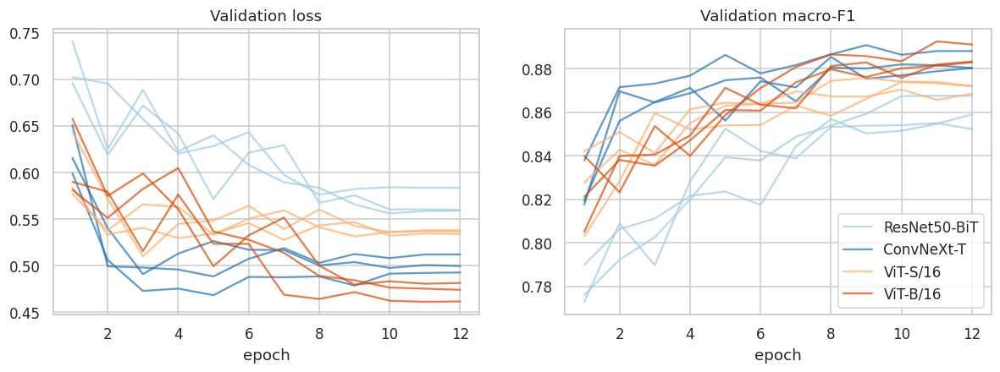

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))                       # validation loss and F1 per epoch
for m in MODELS:
    for s in SEEDS:
        if (m, s) not in runs:
            continue
        h = pd.DataFrame(json.loads(str(runs[(m, s)]['hist'])))     # training history of this run
        lbl = m if s == 0 else None                                 # legend entry only once per model
        ax[0].plot(h.epoch, h.val_loss, c=PALETTE[m], alpha=.7, label=lbl)
        ax[1].plot(h.epoch, h.val_f1, c=PALETTE[m], alpha=.7, label=lbl)
ax[0].set_title('Validation loss')
ax[1].set_title('Validation macro-F1')
ax[1].legend()
for a in ax:
    a.set_xlabel('epoch')
savefig('training_curves')

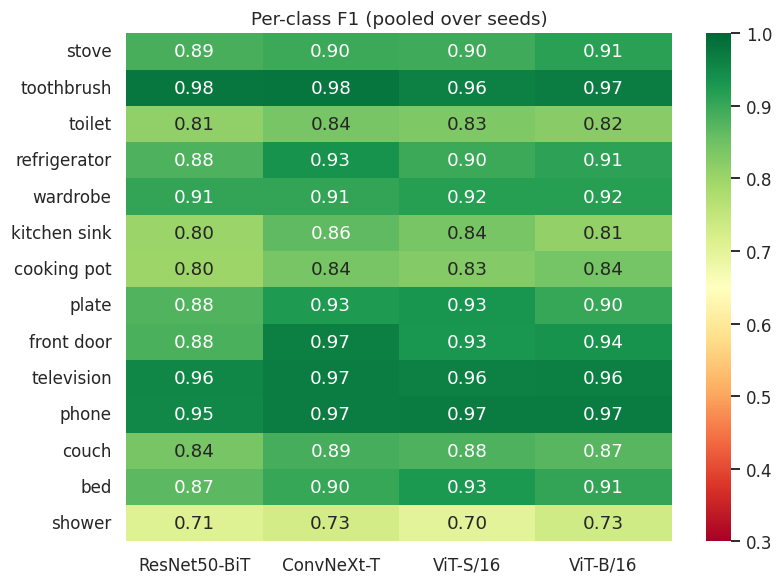

In [20]:
from sklearn.metrics import classification_report
pc = []
for m in MODEL_ORDER:                                    # per-class F1 for each model (all seeds pooled)
    g = P[P.model == m]
    rep = classification_report(g.label, g.pred, labels=range(len(NAMES)), target_names=NAMES,
                                output_dict=True, zero_division=0)
    pc.append(pd.Series({n: rep[n]['f1-score'] for n in NAMES}, name=m))
pc = pd.concat(pc, axis=1)                               # table: classes x models
plt.figure(figsize=(8, 6))
sns.heatmap(pc, annot=True, fmt='.2f', cmap='RdYlGn', vmin=.3, vmax=1)   # green = good, red = poor
plt.title('Per-class F1 (pooled over seeds)')
savefig('per_class_f1')
pc.to_csv(f'{TAB}/per_class_f1.csv')

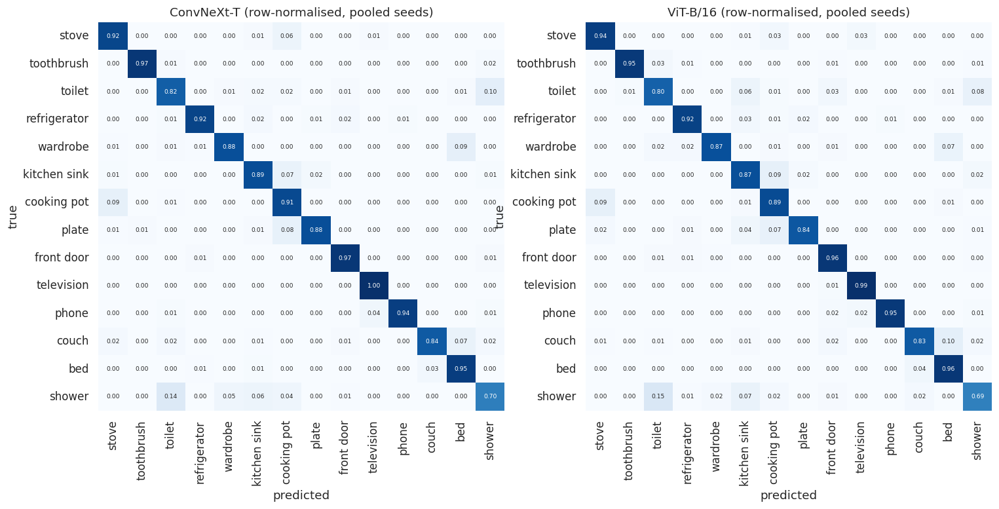

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for a, m in zip(axes, ['ConvNeXt-T', 'ViT-B/16']):              # best-performing CNN-type and ViT-type models
    g = P[P.model == m]
    cm = confusion_matrix(g.label, g.pred, normalize='true')    # rows = true class, sums to 1 per row
    sns.heatmap(cm, ax=a, cmap='Blues', xticklabels=NAMES, yticklabels=NAMES, annot=True, fmt='.2f',
                annot_kws={'size': 6}, cbar=False)
    a.set_title(f'{m} (row-normalised, pooled seeds)')
    a.set_xlabel('predicted')
    a.set_ylabel('true')
savefig('confusion_matrices')

## 8. Fairness analysis: performance across income and region

**Statistical approach.** Test images are clustered by household, so we use a **household-level cluster bootstrap** (B = 5000) for 95% confidence intervals. We resample *households* with replacement and recompute accuracy. Correctness is averaged over the 3 seeds per image.

**Metrics:**
- accuracy per income band
- **income gap** = Acc(Q4) − Acc(Q1)
- **worst-group accuracy**
- **paired bootstrap tests** comparing gaps between architectures

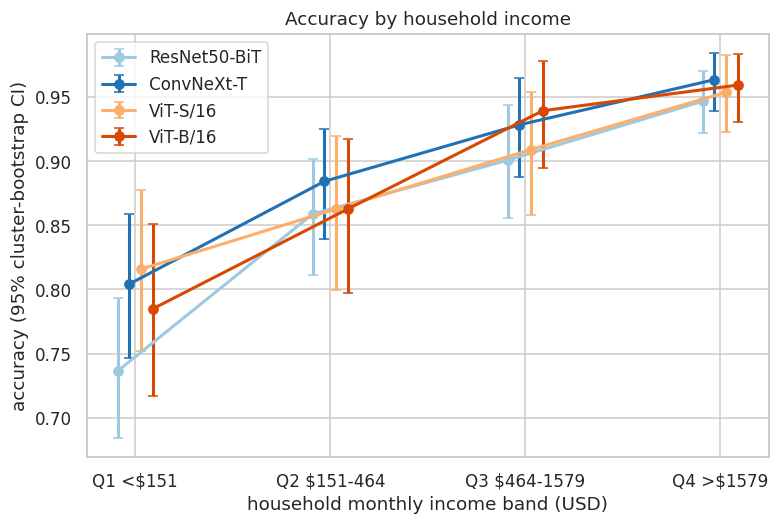

In [22]:
B = 5000                                                                  # number of bootstrap resamples
rng = np.random.default_rng(0)                                            # seeded random generator
hh_codes, hh_index = np.unique(test_df.household, return_inverse=True)    # map each test image to a household number
W = rng.multinomial(len(hh_codes), np.ones(len(hh_codes)) / len(hh_codes), size=B)  # how often each household is drawn in each resample

def correct_matrix(keys):
    """Seed-averaged correctness (0..1) per test image for each variant. keys: {column name: list of runs}."""
    cols = {}
    for col, rs in keys.items():
        cols[col] = np.mean([r['logits'].argmax(1) == test_df.label.values for r in rs], axis=0)  # average over seeds
    return pd.DataFrame(cols, index=test_df.id)

def group_stats(img, group_col, groups):
    """Accuracy per group + bootstrap samples, for every column of `img` (images x variants)."""
    g_of_img = test_df[group_col].values                     # group of each test image
    C = np.zeros((len(hh_codes), len(groups)))               # images per (household, group)
    S = np.zeros((len(hh_codes), len(groups), img.shape[1])) # correct predictions per (household, group, variant)
    for gi, gname in enumerate(groups):
        msk = g_of_img == gname                              # images in this group
        np.add.at(C[:, gi], hh_index[msk], 1)                # count them per household
        for mi, m in enumerate(img.columns):
            np.add.at(S[:, gi, mi], hh_index[msk], img[m].values[msk])  # sum correctness per household
    point = S.sum(0) / C.sum(0)[:, None]                                              # accuracy on the real test set
    boot = np.einsum('bh,hgm->bgm', W, S) / np.einsum('bh,hg->bg', W, C)[..., None]  # accuracy in each resample
    return point, boot

def ci_frame(point, boot, groups, cols):
    """Tidy table with accuracy and 95% CI for every (group, variant)."""
    lo, hi = np.nanpercentile(boot, [2.5, 97.5], axis=0)     # 2.5th and 97.5th percentiles = 95% CI
    parts = [pd.DataFrame(x, index=groups, columns=cols).stack().rename(n) for x, n in [(point, 'acc'), (lo, 'lo'), (hi, 'hi')]]
    return pd.concat(parts, axis=1).reset_index(names=['group', 'model'])

def plot_bands(frame, cols, colors, styles=None, title='', fname=None):
    """Line plot of accuracy per income band with CI error bars."""
    fig, ax = plt.subplots(figsize=(8, 5))
    x = np.arange(len(BANDS))
    for k, m in enumerate(cols):
        d = frame[frame.model == m].set_index('group').loc[BANDS]
        off = (k - (len(cols) - 1) / 2) * 0.06                       # small horizontal shift so bars don't overlap
        ax.errorbar(x + off, d.acc, yerr=[d.acc - d.lo, d.hi - d.acc], marker='o', capsize=3, lw=2,
                    c=colors[m], ls=(styles or {}).get(m, '-'), label=m)
    ax.set_xticks(x, [BAND_LABELS[b] for b in BANDS])
    ax.set_ylabel('accuracy (95% cluster-bootstrap CI)')
    ax.set_xlabel('household monthly income band (USD)')
    ax.legend()
    ax.set_title(title)
    if fname:
        savefig(fname)

main_img = correct_matrix({m: [r for (mm, s), r in runs.items() if mm == m] for m in MODEL_ORDER})  # images x models
inc_point, inc_boot = group_stats(main_img, 'income_band', BANDS)          # accuracy per band (+ bootstrap)
inc = ci_frame(inc_point, inc_boot, BANDS, MODEL_ORDER)
plot_bands(inc, MODEL_ORDER, PALETTE, None, 'Accuracy by household income', 'accuracy_by_income')

In [23]:
q1, q4 = BANDS.index('Q1'), BANDS.index('Q4')
gap_boot = inc_boot[:, q4, :] - inc_boot[:, q1, :]           # gap in every bootstrap resample
gap_point = inc_point[q4] - inc_point[q1]                     # gap on the real test set
gap_ci = np.percentile(gap_boot, [2.5, 97.5], axis=0).T       # 95% CI of the gap
table2 = pd.DataFrame({
    'Acc Q1 (poorest)': inc_point[q1],
    'Acc Q4 (richest)': inc_point[q4],
    'gap Q4-Q1': gap_point,
    'gap 95% CI': [f'[{a:.3f}, {b:.3f}]' for a, b in gap_ci],
    'relative gap %': 100 * gap_point / inc_point[q4],        # gap as % of the richest-band accuracy
    'worst band acc': inc_point.min(0)},                      # accuracy of the worst-served band
    index=MODEL_ORDER).round(3)
table2.to_csv(f'{TAB}/table2_income_gap.csv')
table2

,Acc Q1 (poorest),Acc Q4 (richest),gap Q4-Q1,gap 95% CI,relative gap %,worst band acc
ResNet50-BiT,0.736,0.947,0.210,"[0.148, 0.269]",22.217,0.736
ConvNeXt-T,0.804,0.964,0.159,"[0.098, 0.221]",16.534,0.804
ViT-S/16,0.816,0.954,0.138,"[0.067, 0.207]",14.457,0.816
ViT-B/16,0.785,0.959,0.175,"[0.102, 0.248]",18.189,0.785


**Paired test: does the ViT have a smaller income gap than the CNN?** Both models are evaluated on the same bootstrap resamples, so the difference in their gaps is a paired statistic. A negative difference means the first model has the smaller (fairer) gap.

In [24]:
def paired_gap_test(gb, gp, cols, pairs):
    """Bootstrap test of the difference in income gap between two variants."""
    rows = []
    for a, b in pairs:
        if a not in cols or b not in cols:
            continue
        ia, ib = cols.index(a), cols.index(b)
        d = gb[:, ia] - gb[:, ib]                                # gap difference in every resample
        p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))  # two-sided bootstrap p-value
        rows.append(dict(comparison=f'{a} vs {b}', gap_diff=gp[ia] - gp[ib],
                         ci_lo=np.percentile(d, 2.5), ci_hi=np.percentile(d, 97.5), p_boot=p))
    return pd.DataFrame(rows).round(4)

pairs = [('ViT-S/16', 'ConvNeXt-T'), ('ViT-S/16', 'ResNet50-BiT'), ('ViT-B/16', 'ConvNeXt-T'),
         ('ViT-B/16', 'ResNet50-BiT')]
table3 = paired_gap_test(gap_boot, gap_point, MODEL_ORDER, pairs)
table3.to_csv(f'{TAB}/table3_gap_tests.csv')
table3

,comparison,gap_diff,ci_lo,ci_hi,p_boot
0,ViT-S/16 vs ConvNeXt-T,-0.0214,-0.0591,0.0199,0.2828
1,ViT-S/16 vs ResNet50-BiT,-0.0725,-0.1233,-0.0170,0.0116
2,ViT-B/16 vs ConvNeXt-T,0.0152,-0.0359,0.0732,0.5880
3,ViT-B/16 vs ResNet50-BiT,-0.0358,-0.0853,0.0188,0.1800


**McNemar test.** This checks whether two models differ in overall accuracy on the same images. It counts the images that only one of the two models gets right.

In [25]:
from statsmodels.stats.contingency_tables import mcnemar
maj = main_img >= 0.5                          # an image counts as "correct" if most seeds got it right
rows = []
for a, b in pairs:
    if a not in maj or b not in maj:
        continue
    tb = pd.crosstab(maj[a], maj[b]).reindex(index=[False, True], columns=[False, True], fill_value=0).values  # 2x2 table
    rows.append(dict(comparison=f'{a} vs {b}',
                     a_only_correct=tb[1, 0],          # images only model a gets right
                     b_only_correct=tb[0, 1],          # images only model b gets right
                     p_mcnemar=mcnemar(tb, exact=False, correction=True).pvalue))
pd.DataFrame(rows).round(4)

,comparison,a_only_correct,b_only_correct,p_mcnemar
0,ViT-S/16 vs ConvNeXt-T,20,27,0.3815
1,ViT-S/16 vs ResNet50-BiT,40,28,0.1822
2,ViT-B/16 vs ConvNeXt-T,20,23,0.7604
3,ViT-B/16 vs ResNet50-BiT,33,17,0.0339


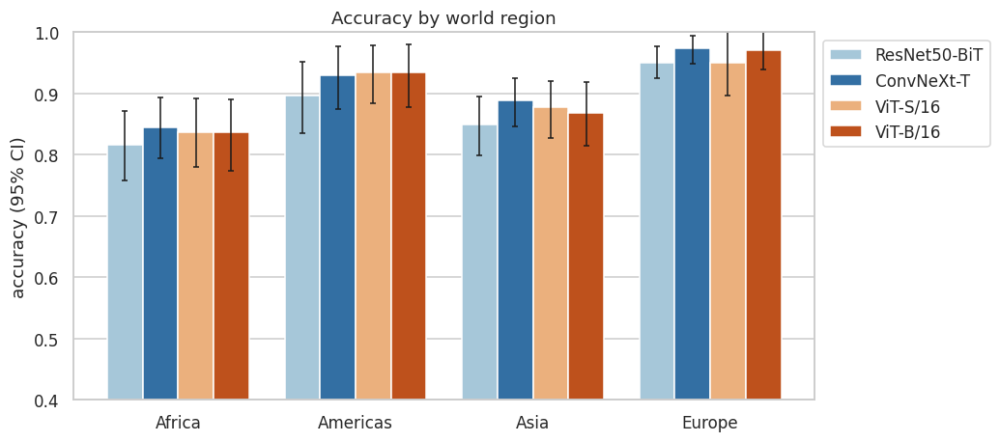

region
Africa      15
Americas    11
Asia        24
Europe       7
Name: test households, dtype: int64


In [26]:
REG = sorted(test_df.region.unique())                                    # list of regions in the test set
reg_point, reg_boot = group_stats(main_img, 'region', REG)               # accuracy per region (+ bootstrap)
reg = ci_frame(reg_point, reg_boot, REG, MODEL_ORDER)
plt.figure(figsize=(9, 4.5))
sns.barplot(reg, x='group', y='acc', hue='model', hue_order=MODEL_ORDER, palette=PALETTE)   # grouped bars
for k, m in enumerate(MODEL_ORDER):                                      # add CI whiskers on each bar
    d = reg[reg.model == m].set_index('group').loc[REG]
    off = (k - (len(MODEL_ORDER) - 1) / 2) * 0.8 / len(MODEL_ORDER)      # x-position of this model's bar
    plt.errorbar(np.arange(len(REG)) + off, d.acc, yerr=[d.acc - d.lo, d.hi - d.acc], fmt='none', c='k', capsize=2, lw=1)
plt.ylim(0.4, 1)
plt.ylabel('accuracy (95% CI)')
plt.xlabel('')
plt.title('Accuracy by world region')
plt.legend(bbox_to_anchor=(1, 1))
savefig('accuracy_by_region')
reg.pivot(index='group', columns='model', values='acc')[MODEL_ORDER].round(3).to_csv(f'{TAB}/acc_by_region.csv')
print(test_df.groupby('region').household.nunique().rename('test households'))   # sample size per region

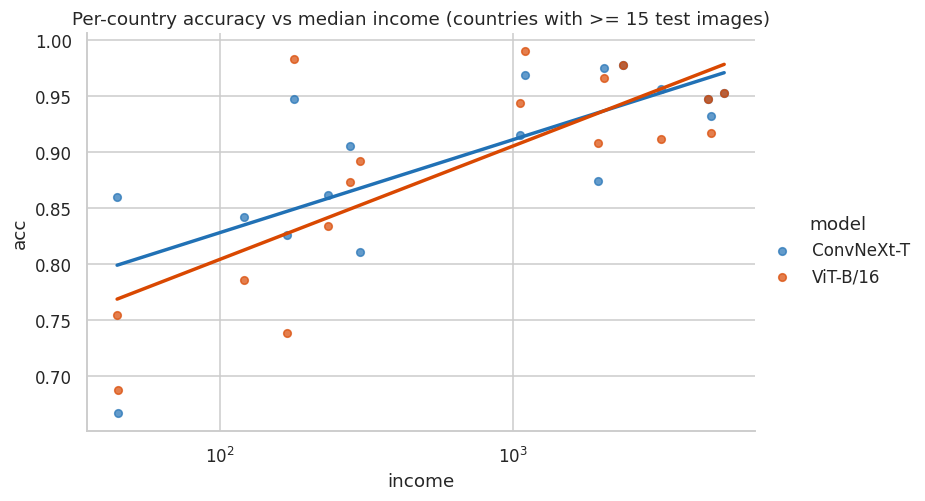

In [27]:
cc = (P.groupby(['model', 'country'])                                      # accuracy per country
        .agg(acc=('correct', 'mean'), n=('id', 'nunique'), income=('income', 'median'))
        .reset_index()
        .query('n >= 15'))                                                 # only countries with enough test images
lm_models = [m for m in ['ConvNeXt-T', 'ViT-B/16'] if m in MODEL_ORDER]
g = sns.lmplot(cc[cc.model.isin(lm_models)], x='income', y='acc', hue='model', hue_order=lm_models,
               palette=PALETTE, logx=True, height=4.5, aspect=1.6, ci=None, scatter_kws=dict(s=25, alpha=.7))  # scatter + trend line
g.ax.set_xscale('log')
g.ax.set_title('Per-country accuracy vs median income (countries with >= 15 test images)')
savefig('accuracy_by_country')

### 8.1 Class-level gaps
Which objects show the biggest gap between rich and poor homes? This shows *where* the bias lives.

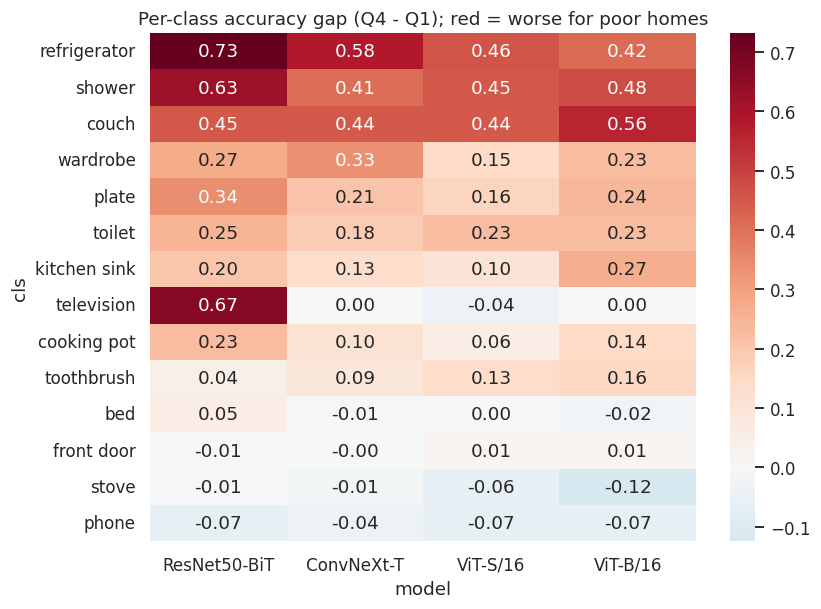

In [28]:
cg = (P[P.income_band.isin(['Q1', 'Q4'])]                                  # only poorest and richest bands
        .groupby(['model', 'cls', 'income_band']).correct.mean()           # accuracy per model, class, band
        .unstack()
        .assign(gap=lambda d: d.Q4 - d.Q1)                                 # gap per class
        .gap.unstack(0)[MODEL_ORDER])                                      # table: classes x models
cg.index = cg.index.map(PRETTY)
cg = cg.loc[cg.mean(1).sort_values(ascending=False).index]                 # biggest average gap at the top
plt.figure(figsize=(8, 6))
sns.heatmap(cg, annot=True, fmt='.2f', cmap='RdBu_r', center=0)            # red = worse for poor homes
plt.title('Per-class accuracy gap (Q4 - Q1); red = worse for poor homes')
savefig('class_income_gap')

## 9. Confound analysis: is it income, or is it image quality, class mix or region?

We fit a logistic regression with household-clustered standard errors:

`correct ~ log10(income) × architecture + region + brightness + sharpness + colourfulness + class`

- The **income coefficient** tells us whether income still predicts errors after controlling for photo quality, object class and region.
- The **income × ViT interaction** directly tests the research question: does the income effect differ between architectures?

In [29]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

R = P.copy()                                               # one row per (model, seed, test image)
for c in ['brightness', 'log_sharpness', 'colorfulness']:   # standardise quality measures (mean 0, std 1)
    R[c + '_z'] = (R[c] - R[c].mean()) / R[c].std()
R['log_inc_c'] = R.log_income - R.log_income.mean()         # centre log-income (makes coefficients easier to read)
R['vit'] = (R.family == 'ViT').astype(int)                  # 1 = ViT, 0 = CNN
R['hh'] = pd.factorize(R.household)[0]                      # household as an integer (for clustered errors)

def fit(data, formula):
    """Logistic regression with standard errors clustered by household."""
    return smf.glm(formula, data=data, family=sm.families.Binomial()).fit(cov_type='cluster', cov_kwds={'groups': data.hh})

controls = 'C(region) + brightness_z + log_sharpness_z + colorfulness_z + C(cls)'   # control variables
naive = fit(R, 'correct ~ log_inc_c * vit')                          # model without controls
pooled = fit(R, f'correct ~ log_inc_c * vit + {controls}')           # model with controls

keep = ['log_inc_c', 'vit', 'log_inc_c:vit', 'brightness_z', 'log_sharpness_z', 'colorfulness_z']  # rows to report
def or_table(res, label):
    """Convert regression coefficients to odds ratios with 95% CI."""
    ci = res.conf_int()
    t = pd.DataFrame({'OR': np.exp(res.params), 'OR_lo': np.exp(ci[0]), 'OR_hi': np.exp(ci[1]), 'p': res.pvalues})
    return t.loc[[k for k in keep if k in t.index]].assign(model=label)
table4 = pd.concat([or_table(naive, 'naive (income x arch only)'), or_table(pooled, 'with controls')]).round(4)
table4.to_csv(f'{TAB}/table4_regression.csv')
table4

,OR,OR_lo,OR_hi,p,model
log_inc_c,2.9836,2.0858,4.2678,0.0000,naive (income x arch only)
vit,1.0810,0.9344,1.2507,0.2948,naive (income x arch only)
log_inc_c:vit,1.0040,0.8080,1.2475,0.9715,naive (income x arch only)
log_inc_c,3.0761,1.7015,5.5611,0.0002,with controls
vit,1.0865,0.9316,1.2670,0.2904,with controls
log_inc_c:vit,1.0013,0.7947,1.2617,0.9913,with controls
brightness_z,0.9201,0.7408,1.1429,0.4517,with controls
log_sharpness_z,1.0217,0.8303,1.2573,0.8390,with controls
colorfulness_z,1.2054,0.9347,1.5546,0.1500,with controls


**Interpretation guide.**
- OR(`log_inc_c`) > 1 means a 10× increase in income multiplies the odds of a correct prediction by OR, for the CNN reference group.
- OR(`log_inc_c:vit`) < 1 means ViTs depend *less* on income; > 1 means they depend *more*.
- If the income OR shrinks substantially from "naive" to "with controls", part of the gap is explained by image quality or class mix rather than by object appearance.

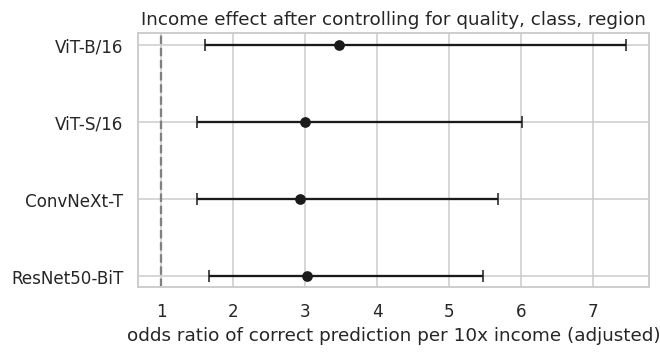

,model,OR_income,lo,hi,p
0,ResNet50-BiT,3.0194,1.6675,5.4673,0.0003
1,ConvNeXt-T,2.9228,1.5027,5.6847,0.0016
2,ViT-S/16,2.9977,1.4965,6.0049,0.0020
3,ViT-B/16,3.4671,1.6119,7.4575,0.0015


In [30]:
rows = []
for m in MODELS:                                                      # separate regression per model
    res = fit(R[R.model == m], f'correct ~ log_inc_c + {controls}')
    lo, hi = np.exp(res.conf_int().loc['log_inc_c'])
    rows.append(dict(model=m, OR_income=np.exp(res.params['log_inc_c']), lo=lo, hi=hi, p=res.pvalues['log_inc_c']))
per_model_or = pd.DataFrame(rows)
plt.figure(figsize=(6, 3))
plt.errorbar(per_model_or.OR_income, per_model_or.model,
             xerr=[per_model_or.OR_income - per_model_or.lo, per_model_or.hi - per_model_or.OR_income],
             fmt='o', capsize=4, c='k')                               # odds ratio with 95% CI
plt.axvline(1, ls='--', c='grey')                                     # OR = 1 means "no income effect"
plt.xlabel('odds ratio of correct prediction per 10x income (adjusted)')
plt.title('Income effect after controlling for quality, class, region')
savefig('income_odds_ratios')
per_model_or.round(4)

## 10. Calibration across income groups
A model that is *confidently* wrong on poorer homes is more harmful than one that signals uncertainty. We measure Expected Calibration Error (ECE, 15 bins) per band. ECE is the average gap between confidence and actual accuracy.

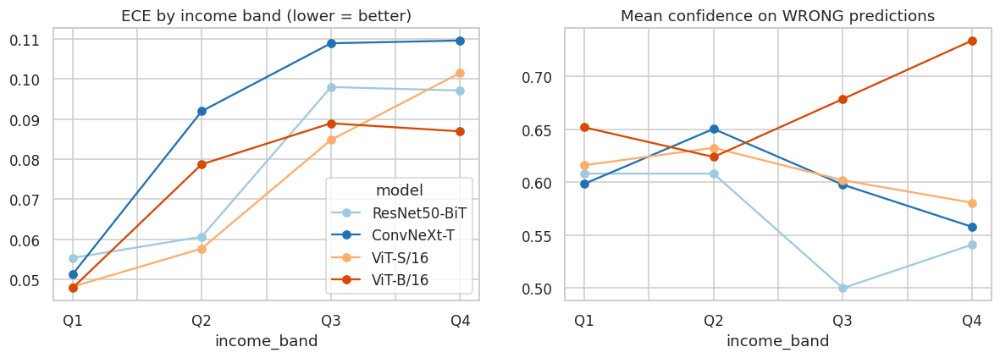

income_band,Q1,Q2,Q3,Q4
model,,,,
ResNet50-BiT,0.055,0.061,0.098,0.097
ConvNeXt-T,0.051,0.092,0.109,0.110
ViT-S/16,0.048,0.058,0.085,0.101
ViT-B/16,0.048,0.079,0.089,0.087


In [31]:
def ece(conf, correct, bins=15):
    """Expected Calibration Error: weighted average |accuracy - confidence| over confidence bins."""
    edges = np.linspace(0, 1, bins + 1)                               # bin boundaries 0, 1/15, ..., 1
    idx = np.clip(np.digitize(conf, edges) - 1, 0, bins - 1)          # bin of each prediction
    total = 0.0
    for b in range(bins):
        in_bin = idx == b
        if in_bin.any():
            total += abs(correct[in_bin].mean() - conf[in_bin].mean()) * in_bin.mean()  # gap x share of predictions
    return total

cal = (P.groupby(['model', 'income_band'])
         .apply(lambda g: ece(g.conf.values, g.correct.values))
         .unstack()[BANDS].reindex(MODEL_ORDER))                                        # ECE per model and band
conf_wrong = (P[P.correct == 0].groupby(['model', 'income_band']).conf.mean()
                .unstack()[BANDS].reindex(MODEL_ORDER))                                 # confidence when wrong
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
cal.T.plot(marker='o', ax=ax[0], color=[PALETTE[m] for m in cal.index])
ax[0].set_title('ECE by income band (lower = better)')
conf_wrong.T.plot(marker='o', ax=ax[1], color=[PALETTE[m] for m in cal.index], legend=False)
ax[1].set_title('Mean confidence on WRONG predictions')
savefig('calibration_by_income')
cal.round(3)

## 11. Representation analysis
1. **t-SNE** squeezes the high-dimensional embeddings (seed 0) into 2-D, showing how each architecture organises the test images.
2. **Income probe.** If a linear classifier can predict a household's income band from the *object* embedding, the model has encoded socioeconomic context. This is a source of potential shortcut learning and of privacy leakage.

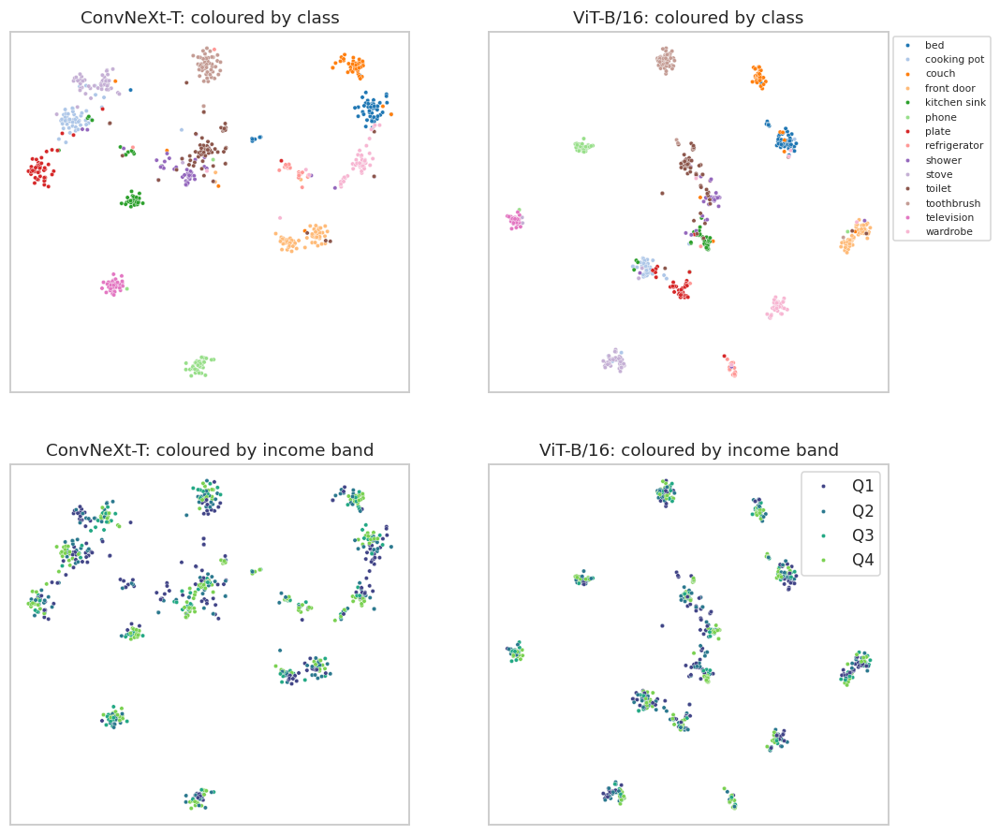

chance level = 0.25 (4 bands)


,model,income_probe_bal_acc,std
0,ResNet50-BiT,0.523,0.032
1,ConvNeXt-T,0.492,0.026
2,ViT-S/16,0.516,0.036
3,ViT-B/16,0.516,0.042


In [32]:
from sklearn.manifold import TSNE
from sklearn.model_selection import GroupKFold, cross_val_score

show = [m for m in ['ConvNeXt-T', 'ViT-B/16'] if (m, 0) in runs]    # models to visualise
fig, axes = plt.subplots(2, len(show), figsize=(5.5 * len(show), 10))
axes = np.array(axes).reshape(2, -1)
for j, m in enumerate(show):
    Z = TSNE(n_components=2, init='pca', perplexity=30, random_state=0).fit_transform(runs[(m, 0)]['emb'])  # 2-D map
    last = j == len(show) - 1                                                   # legend only on the last column
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=test_df.cls.map(PRETTY), s=8, ax=axes[0, j], legend=last, palette='tab20')
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=test_df.income_band, hue_order=BANDS, s=8, ax=axes[1, j], legend=last, palette='viridis')
    axes[0, j].set_title(f'{m}: coloured by class')
    axes[1, j].set_title(f'{m}: coloured by income band')
    for a in axes[:, j]:
        a.set_xticks([])
        a.set_yticks([])
axes[0, -1].legend(bbox_to_anchor=(1, 1), fontsize=7)
axes[1, -1].legend(bbox_to_anchor=(1, 1))
savefig('tsne_embeddings')

rows = []
for m in MODEL_ORDER:                                                          # can income be read from the embedding?
    if (m, 0) not in runs:
        continue
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1))
    s = cross_val_score(clf, runs[(m, 0)]['emb'], test_df.income_band, groups=test_df.household,
                        cv=GroupKFold(5), scoring='balanced_accuracy')          # 5-fold, households never split
    rows.append(dict(model=m, income_probe_bal_acc=s.mean(), std=s.std()))
probe_income = pd.DataFrame(rows).round(3)
probe_income.to_csv(f'{TAB}/income_probe.csv')
print('chance level = 0.25 (4 bands)')
probe_income

## 12. Additional experiment results

### 12.1 Learning-rate sensitivity (validation macro-F1, seed 0)
If the default learning rate is best, or within about 0.01 of the best, for both architectures, the comparison is not biased by tuning.

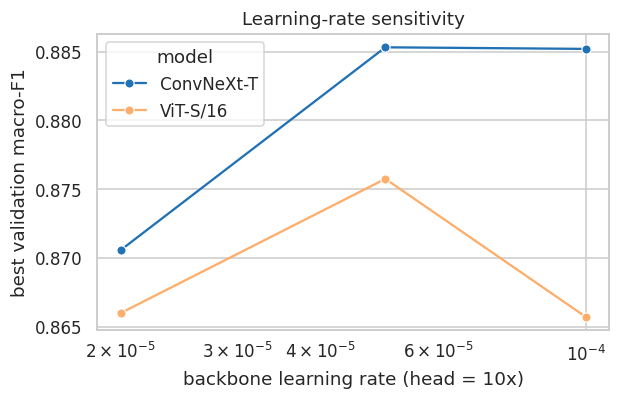

model,ConvNeXt-T,ViT-S/16
lr,,
0.00002,0.8706,0.8660
0.00005,0.8853,0.8758
0.00010,0.8852,0.8657


In [33]:
rows = []
for name in MITIGATE:
    rows.append(dict(model=name, lr=CFG['lr_backbone'], val_f1=float(runs[(name, 0)]['best_val_f1'])))  # default LR (main run)
    for lr in LR_GRID:
        key = (name, f'lr{lr:g}', 0)
        if key in extra:
            rows.append(dict(model=name, lr=lr, val_f1=float(extra[key]['best_val_f1'])))  # alternative LRs
lr_tab = pd.DataFrame(rows).sort_values(['model', 'lr'])
plt.figure(figsize=(6, 3.5))
sns.lineplot(lr_tab, x='lr', y='val_f1', hue='model', marker='o', palette=PALETTE)
plt.xscale('log')
plt.xlabel('backbone learning rate (head = 10x)')
plt.ylabel('best validation macro-F1')
plt.title('Learning-rate sensitivity')
savefig('lr_sensitivity')
lr_tab.to_csv(f'{TAB}/lr_sensitivity.csv', index=False)
lr_tab.pivot(index='lr', columns='model', values='val_f1').round(4)

### 12.2 Linear probe (frozen) vs full fine-tuning
Does adapting the backbone help accuracy, and does it narrow or widen the income gap?

,overall acc,Acc Q1,Acc Q4,gap Q4-Q1,gap 95% CI
ResNet50-BiT (fine-tuned),0.866,0.736,0.947,0.210,"[0.148, 0.269]"
ResNet50-BiT (linear probe),0.849,0.750,0.920,0.170,"[0.092, 0.249]"
ConvNeXt-T (fine-tuned),0.899,0.804,0.964,0.159,"[0.098, 0.221]"
ConvNeXt-T (linear probe),0.880,0.762,0.945,0.184,"[0.112, 0.258]"
ViT-S/16 (fine-tuned),0.890,0.816,0.954,0.138,"[0.067, 0.207]"
ViT-S/16 (linear probe),0.874,0.756,0.941,0.185,"[0.118, 0.255]"
ViT-B/16 (fine-tuned),0.890,0.785,0.959,0.175,"[0.102, 0.248]"
ViT-B/16 (linear probe),0.894,0.808,0.958,0.150,"[0.081, 0.218]"


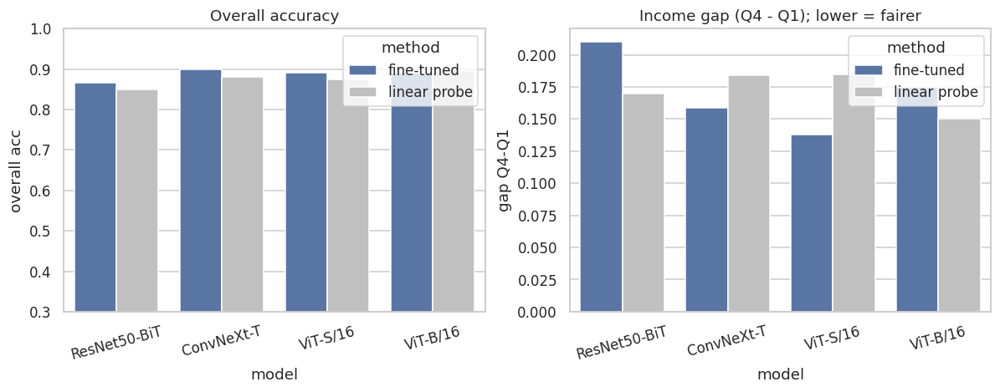

In [34]:
variants = {}
for m in MODELS:
    variants[f'{m} (fine-tuned)'] = [r for (mm, s), r in runs.items() if mm == m]   # 3 seeds
    if (m, 'probe', 0) in extra:
        variants[f'{m} (linear probe)'] = [extra[(m, 'probe', 0)]]                   # 1 deterministic run
fp_img = correct_matrix(variants)                                  # images x variants
fp_point, fp_boot = group_stats(fp_img, 'income_band', BANDS)
fp_gap_boot = fp_boot[:, q4, :] - fp_boot[:, q1, :]
cols = list(fp_img.columns)
fp_tab = pd.DataFrame({
    'overall acc': fp_img.mean().values,
    'Acc Q1': fp_point[q1], 'Acc Q4': fp_point[q4],
    'gap Q4-Q1': fp_point[q4] - fp_point[q1],
    'gap 95% CI': [f'[{a:.3f}, {b:.3f}]' for a, b in np.percentile(fp_gap_boot, [2.5, 97.5], axis=0).T]},
    index=cols).round(3)
fp_tab.to_csv(f'{TAB}/probe_vs_finetune.csv')
display(fp_tab)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_df = fp_tab.reset_index(names='variant')
plot_df['model'] = plot_df.variant.str.split(r' \(').str[0]                     # model name
plot_df['method'] = plot_df.variant.str.extract(r'\((.*)\)')[0]                # 'fine-tuned' or 'linear probe'
sns.barplot(plot_df, x='model', y='overall acc', hue='method', ax=ax[0], palette=['#4c72b0', '#c0c0c0'])
ax[0].set_title('Overall accuracy')
ax[0].set_ylim(0.3, 1)
sns.barplot(plot_df, x='model', y='gap Q4-Q1', hue='method', ax=ax[1], palette=['#4c72b0', '#c0c0c0'])
ax[1].set_title('Income gap (Q4 - Q1); lower = fairer')
for a in ax:
    a.tick_params(axis='x', rotation=15)
savefig('probe_vs_finetune')

### 12.3 Bias mitigation: income-balanced sampling vs standard training

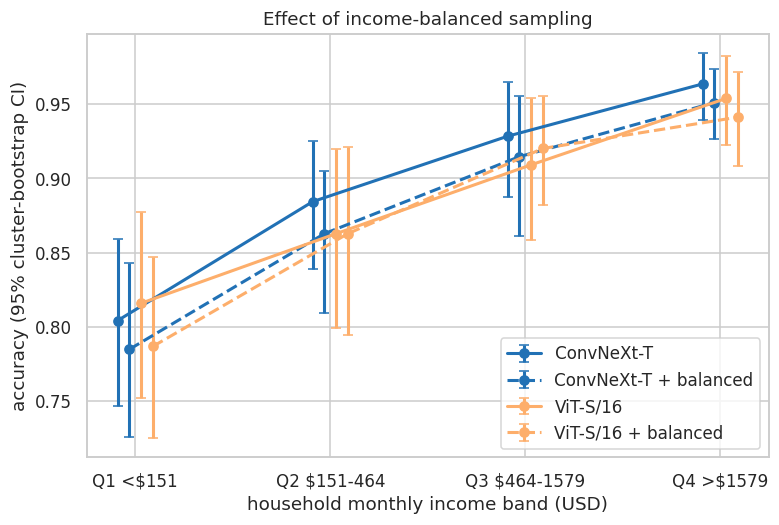

,overall acc,Acc Q1,Acc Q4,gap Q4-Q1,worst band acc
ConvNeXt-T,0.899,0.804,0.964,0.159,0.804
ConvNeXt-T + balanced,0.883,0.785,0.951,0.166,0.785
ViT-S/16,0.890,0.816,0.954,0.138,0.816
ViT-S/16 + balanced,0.881,0.787,0.941,0.154,0.787


Negative gap_diff = balanced sampling REDUCED the income gap


,comparison,gap_diff,ci_lo,ci_hi,p_boot
0,ConvNeXt-T + balanced vs ConvNeXt-T,0.0068,-0.0235,0.0385,0.6660
1,ViT-S/16 + balanced vs ViT-S/16,0.0165,-0.0028,0.0368,0.0904


In [35]:
mit_variants = {}
for m in MITIGATE:
    mit_variants[m] = [r for (mm, s), r in runs.items() if mm == m]                                  # standard training
    bal = [r for (mm, t, s), r in extra.items() if mm == m and t == 'balanced']                      # balanced sampling
    if bal:
        mit_variants[f'{m} + balanced'] = bal
mit_img = correct_matrix(mit_variants)
mit_point, mit_boot = group_stats(mit_img, 'income_band', BANDS)
mit_cols = list(mit_img.columns)
mit_frame = ci_frame(mit_point, mit_boot, BANDS, mit_cols)
mit_colors = {c: PALETTE[c.split(' +')[0]] for c in mit_cols}                    # same colour per architecture
mit_styles = {c: '--' if 'balanced' in c else '-' for c in mit_cols}             # dashed = balanced sampling
plot_bands(mit_frame, mit_cols, mit_colors, mit_styles, 'Effect of income-balanced sampling', 'mitigation_by_income')

mit_gap_boot = mit_boot[:, q4, :] - mit_boot[:, q1, :]
mit_gap_point = mit_point[q4] - mit_point[q1]
mit_tab = pd.DataFrame({
    'overall acc': mit_img.mean().values,
    'Acc Q1': mit_point[q1], 'Acc Q4': mit_point[q4],
    'gap Q4-Q1': mit_gap_point,
    'worst band acc': mit_point.min(0)}, index=mit_cols).round(3)
mit_tab.to_csv(f'{TAB}/mitigation.csv')
display(mit_tab)

mit_pairs = [(f'{m} + balanced', m) for m in MITIGATE]                            # balanced vs standard, same model
mit_tests = paired_gap_test(mit_gap_boot, mit_gap_point, mit_cols, mit_pairs)
mit_tests.to_csv(f'{TAB}/mitigation_tests.csv')
print('Negative gap_diff = balanced sampling REDUCED the income gap')
mit_tests

## 13. Explainability: what are the models looking at?
We compare Grad-CAM (Selvaraju et al., 2017) for the CNN (ConvNeXt-T, final stage) and the ViT (ViT-B/16, last block's pre-attention LayerNorm, with tokens reshaped to a 14×14 grid). The heat-maps show which pixels drove each prediction. We focus on cases where the two architectures disagree on images from low-income homes.

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

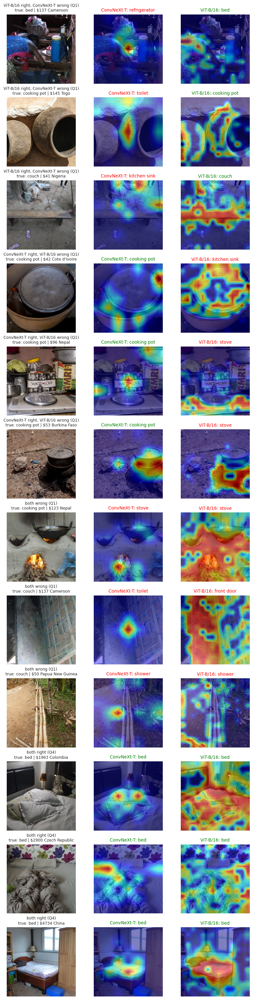

In [36]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def get_layer(model, path):
    """Find a layer by a dotted path such as 'blocks.11.norm1'."""
    for p in path.split('.'):
        model = model[int(p)] if p.isdigit() else getattr(model, p)   # numbers index lists, names are attributes
    return model

def load_trained(name):
    """Rebuild a model and load its fine-tuned seed-0 weights."""
    m = build_model(name)
    m.load_state_dict(torch.load(f'{CKPT}/{slug(name)}_s0.pt', map_location='cpu'))
    return m.to(DEVICE).eval()

def make_cam(name, model):
    """Create a Grad-CAM object. ViTs output tokens, not a 2-D map, so we reshape tokens to a 14x14 grid."""
    reshape = None
    if MODELS[name]['family'] == 'ViT':
        npt = getattr(model, 'num_prefix_tokens', 1)                 # number of special tokens (the [CLS] token)
        def reshape(t):
            t = t[:, npt:, :]                                        # drop the [CLS] token
            s = int(t.size(1) ** .5)                                 # 196 patches -> 14 x 14
            return t.reshape(t.size(0), s, s, t.size(2)).permute(0, 3, 1, 2)  # (batch, channels, 14, 14)
    return GradCAM(model=model, target_layers=[get_layer(model, MODELS[name]['cam_layer'])], reshape_transform=reshape)

CAM_MODELS = [m for m in ['ConvNeXt-T', 'ViT-B/16'] if os.path.exists(f'{CKPT}/{slug(m)}_s0.pt')]
s0 = P[P.seed == 0].pivot(index='id', columns='model', values='pred').reindex(test_df.id)   # seed-0 predictions
lab = test_df.set_index('id').label                                                       # true labels
a, b = CAM_MODELS
low = (test_df.income_band == 'Q1').values                         # poorest-band images
right_a, right_b = (s0[a] == lab).values, (s0[b] == lab).values    # who got each image right
cases = {                                                          # pick 3 example images for each situation
    f'{b} right, {a} wrong (Q1)': test_df.id[low & right_b & ~right_a].head(3),
    f'{a} right, {b} wrong (Q1)': test_df.id[low & right_a & ~right_b].head(3),
    'both wrong (Q1)': test_df.id[low & ~right_a & ~right_b].head(3),
    'both right (Q4)': test_df.id[(test_df.income_band == 'Q4').values & right_a & right_b].head(3),
}
sel = [(k, i) for k, ids in cases.items() for i in ids]           # flat list of (case, image id)
meta = test_df.set_index('id')

cams = {}
for name in CAM_MODELS:
    model = load_trained(name)
    _, te_tf = make_tfms(model)
    cam = make_cam(name, model)
    for _, i in sel:
        x = te_tf(Image.open(f'{IMG_DIR}/{meta.loc[i].file}').convert('RGB')).unsqueeze(0).to(DEVICE)  # 1-image batch
        pred = int(s0.loc[i, name])                                                            # explain the predicted class
        cams[(name, i)] = (cam(input_tensor=x, targets=[ClassifierOutputTarget(pred)])[0], pred)
    del model, cam
    torch.cuda.empty_cache()

disp = T.Compose([T.Resize(256), T.CenterCrop(224)])               # same crop the models saw
fig, axes = plt.subplots(len(sel), 3, figsize=(9, 3 * len(sel)))
for row, (case, i) in enumerate(sel):
    r = meta.loc[i]
    rgb = np.asarray(disp(Image.open(f'{IMG_DIR}/{r.file}').convert('RGB')), dtype=np.float32) / 255
    axes[row, 0].imshow(rgb)                                       # original image
    axes[row, 0].set_title(f'{case}\ntrue: {PRETTY[r.cls]} | ${r.income:.0f} {r.country}', fontsize=8)
    for j, name in enumerate(CAM_MODELS):
        heat, pred = cams[(name, i)]
        axes[row, j + 1].imshow(show_cam_on_image(rgb, heat, use_rgb=True))   # heat-map overlay
        axes[row, j + 1].set_title(f'{name}: {NAMES[pred]}', fontsize=9, color='green' if pred == r.label else 'red')
for ax_ in axes.ravel():
    ax_.axis('off')
savefig('gradcam_comparison')

## 14. Sample outputs: the same object in the poorest vs richest homes

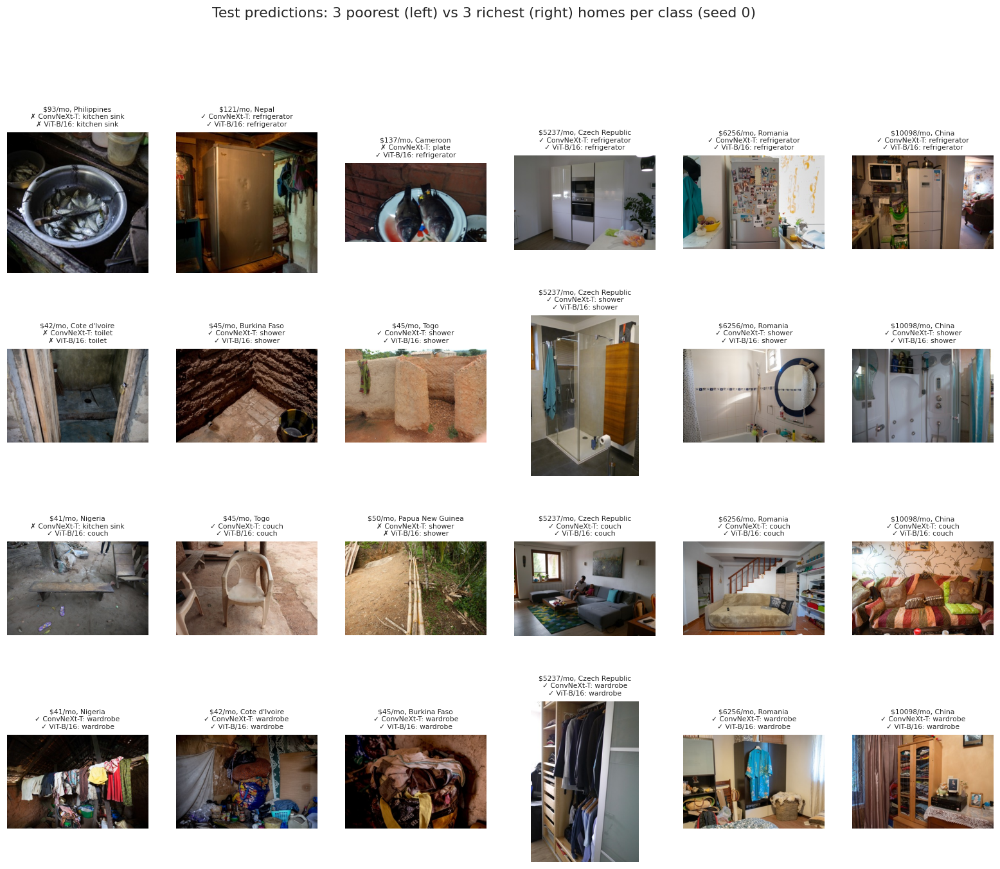

In [37]:
def gallery(classes, n=3):
    """For each class, show the n poorest and n richest test images with every model's prediction."""
    models = [m for m in ['ConvNeXt-T', 'ViT-B/16'] if m in MODEL_ORDER]
    fig, axes = plt.subplots(len(classes), 2 * n, figsize=(6 * n, 3.4 * len(classes)))
    for i, c in enumerate(classes):
        sub = test_df[test_df.cls == c].sort_values('income')
        for j, (_, r) in enumerate(pd.concat([sub.head(n), sub.tail(n)]).iterrows()):
            a_ = axes[i, j]
            a_.imshow(Image.open(f'{IMG_DIR}/{r.file}'))
            a_.axis('off')
            preds = [(m, NAMES[int(s0.loc[r.id, m])]) for m in models]                          # each model's guess
            txt = '\n'.join(f"{'✓' if p == PRETTY[c] else '✗'} {m}: {p}" for m, p in preds)      # tick or cross
            a_.set_title(f'${r.income:.0f}/mo, {r.country}\n{txt}', fontsize=7)
    fig.suptitle('Test predictions: 3 poorest (left) vs 3 richest (right) homes per class (seed 0)', y=1.0)
    savefig('sample_predictions')

worst = cg.mean(1).sort_values(ascending=False).index[:4]                   # 4 classes with the largest income gap
gallery([{v: k for k, v in PRETTY.items()}[w] for w in worst])

## 15. Summary for the report

In [38]:
print('=== Table 1: overall ===');                display(table1)
print('=== Table 2: income gap ===');             display(table2)
print('=== Table 3: paired gap tests ===');       display(table3)
print('=== Table 4: regression (odds ratios) ==='); display(table4)
print('=== Linear probe vs fine-tune ===');       display(fp_tab)
print('=== Mitigation ===');                      display(mit_tab); display(mit_tests)
print('Figures saved to', FIG)
print(sorted(os.listdir(FIG)))

=== Table 1: overall ===


,family,params (M),accuracy,macro-F1,balanced acc,train time (min),inference (img/s)
model,,,,,,,
ResNet50-BiT,CNN,23.5,0.866 ± 0.004,0.868 ± 0.002,0.867 ± 0.003,6.1,321.0
ConvNeXt-T,CNN,27.8,0.899 ± 0.004,0.901 ± 0.004,0.900 ± 0.006,6.7,353.0
ViT-S/16,ViT,21.7,0.890 ± 0.002,0.891 ± 0.002,0.891 ± 0.003,4.2,429.0
ViT-B/16,ViT,85.8,0.890 ± 0.002,0.891 ± 0.003,0.891 ± 0.003,8.9,292.0


=== Table 2: income gap ===


,Acc Q1 (poorest),Acc Q4 (richest),gap Q4-Q1,gap 95% CI,relative gap %,worst band acc
ResNet50-BiT,0.736,0.947,0.210,"[0.148, 0.269]",22.217,0.736
ConvNeXt-T,0.804,0.964,0.159,"[0.098, 0.221]",16.534,0.804
ViT-S/16,0.816,0.954,0.138,"[0.067, 0.207]",14.457,0.816
ViT-B/16,0.785,0.959,0.175,"[0.102, 0.248]",18.189,0.785


=== Table 3: paired gap tests ===


...

,overall acc,Acc Q1,Acc Q4,gap Q4-Q1,gap 95% CI
ResNet50-BiT (fine-tuned),0.866,0.736,0.947,0.210,"[0.148, 0.269]"
ResNet50-BiT (linear probe),0.849,0.750,0.920,0.170,"[0.092, 0.249]"
ConvNeXt-T (fine-tuned),0.899,0.804,0.964,0.159,"[0.098, 0.221]"
ConvNeXt-T (linear probe),0.880,0.762,0.945,0.184,"[0.112, 0.258]"
ViT-S/16 (fine-tuned),0.890,0.816,0.954,0.138,"[0.067, 0.207]"
ViT-S/16 (linear probe),0.874,0.756,0.941,0.185,"[0.118, 0.255]"
ViT-B/16 (fine-tuned),0.890,0.785,0.959,0.175,"[0.102, 0.248]"
ViT-B/16 (linear probe),0.894,0.808,0.958,0.150,"[0.081, 0.218]"


=== Mitigation ===


,overall acc,Acc Q1,Acc Q4,gap Q4-Q1,worst band acc
ConvNeXt-T,0.899,0.804,0.964,0.159,0.804
ConvNeXt-T + balanced,0.883,0.785,0.951,0.166,0.785
ViT-S/16,0.890,0.816,0.954,0.138,0.816
ViT-S/16 + balanced,0.881,0.787,0.941,0.154,0.787


,comparison,gap_diff,ci_lo,ci_hi,p_boot
0,ConvNeXt-T + balanced vs ConvNeXt-T,0.0068,-0.0235,0.0385,0.6660
1,ViT-S/16 + balanced vs ViT-S/16,0.0165,-0.0028,0.0368,0.0904


Figures saved to /content/drive/MyDrive/dollarstreet_vit_vs_cnn/figures
['accuracy_by_country.png', 'accuracy_by_income.png', 'accuracy_by_region.png', 'calibration_by_income.png', 'class_income_gap.png', 'confusion_matrices.png', 'eda_class_by_income.png', 'eda_low_vs_high.png', 'eda_overview.png', 'eda_quality_by_income.png', 'gradcam_comparison.png', 'income_odds_ratios.png', 'lr_sensitivity.png', 'mitigation_by_income.png', 'per_class_f1.png', 'probe_vs_finetune.png', 'sample_predictions.png', 'training_curves.png', 'tsne_embeddings.png']
